# COVID-19 Exit Strategies in an Individual-Based Transmission Model: Active Subspaces of Intensive-Care Load

__Federica Gugole__, Centrum Wiskunde & Informatica, Amsterdam, The Netherlands

__Luc E. Coffeng__, Department of Public Health, Erasmus MC, University Medical Center Rotterdam, Rotterdam, The Netherlands

__Wouter Edeling__, Centrum Wiskunde & Informatica, Amsterdam, The Netherlands

__Benjamin Sanderse__, Centrum Wiskunde & Informatica, Amsterdam, The Netherlands

__Sake J. de Vlas__, Department of Public Health, Erasmus MC, University Medical Center Rotterdam, Rotterdam, The Netherlands

__Daan Crommelin__, Centrum Wiskunde & Informatica, Amsterdam, and Korteweg-de Vries Institute for Mathematics, University of Amsterdam, Amsterdam, The Netherlands

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the runs were made for this repository with virsim 1.0.5, an R package by L. E. Coffeng, an outside code that is not in the repository. The R driver (`R/strategies.R`, `R/run_chunk.R`), `generate_data.py` and `convert_data.py` record how the files were made; `DATA.md` gives the install-and-run recipe, versions and run times. virsim is needed only to regenerate the runs.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 568                      # the only seed in this notebook (bootstrap and noise null)
t_start = time.perf_counter()
STRATS = ['FC', 'CT', 'IL', 'PO']
QOIS = ['IC_prev_avg_max', 'IC_excess_days']
QLAB = {'IC_prev_avg_max': 'QoI 1, peak 30-day mean IC prevalence (per million)',
        'IC_excess_days': 'QoI 2, IC patient-days above capacity (per million)'}
IC_CAPACITY = 109.0             # IC beds per million (paper p. 6)

### Summary

Gugole et al. [[1]](#references) quantify the uncertainty of four COVID-19 exit strategies in virsim, a stochastic individual-based SEIR model of one million people: Flattening the Curve (FC), Contact Tracing (CT), Intermittent Lockdown (IL) and Phased Opening (PO), each with its own 6 to 8 uncertain inputs from their Table 1, and two intensive-care (IC) quantities of interest. We ran virsim on a 512-point scrambled Sobol' design per strategy (plus 60 seed replicates) and estimate active subspaces without gradients, by the global quadratic (QPHD) estimator in inputs mapped through their CDFs to standard normals. Every strategy has one dominant direction ($\lambda_1/\lambda_2$ from 10.4 to 16.0), led by the strategy's main policy inputs (uptake, intervention effect, tracing rate) and, except for CT, by $R_0$; by one rule for all strategies (the last eigenvalue gap of at least 8 with a stable subspace) FC and IL have a two-dimensional and CT and PO a three-dimensional active subspace, CT's spanned mostly by its three tracing inputs; the seed noise, measured on the replicates, is 0.2 to 3.9 % of the QoI variance, so it limits the leave-one-out $R^2$ of cubic fits on these subspaces (0.903 to 0.973) only slightly, but it hides every eigenvalue below roughly $10^{-4}$ to $3\times10^{-3}$ of $\lambda_1$.

### Active subspaces in brief

For a function $f(\mathbf z)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf z = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf z$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree polynomial in $\mathbf y$ can stand in for $f$. virsim is stochastic and gives no gradients, so here $\mathbf C$ is estimated from values: a quadratic $q(\mathbf z) = c + \mathbf g^T\mathbf z + \tfrac12\mathbf z^T\mathbf H\mathbf z$ is fitted by least squares, and $\hat{\mathbf C} = \mathbb E[\nabla q\,\nabla q^T] = \mathbf g\mathbf g^T + \mathbf H^2$ for standard normal $\mathbf z$ (principal Hessian directions [[5]](#references); the library's `"qphd"` estimator). See P. G. Constantine [[4]](#references), [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

virsim [[2]](#references) is an individual-based (agent-based) meta-population model of SARS-CoV-2 transmission: susceptible, exposed, infectious and recovered agents with life-long immunity, grouped in clusters (towns) and superclusters (provinces) [1, pp. 3-4]; de Vlas and Coffeng [[3]](#references) describe it. The study simulates one million agents for 550 days (pp. 4-5); the driver uses 1000 clusters and 20 superclusters, the values in the paper's study scripts (its ref. [28]). The contact rate is $R_0$ divided by `avg_duration_infectiousness` (p. 9); the inter-individual variation of the intervention effect is $1/x$ with $x$ = `intervention_effect_var_inv` drawn from Table 1 (p. 9); the latent period is Weibull with mean 4.6 days and shape `shape_exposed_time`, and the infectious period is exponential with mean `avg_duration_infectiousness` (study scripts). All strategies are preceded by a lockdown (p. 4): transmission at 30 % for one week, then 15 %, for 60 days in all, then a partial lockdown at 25 %, and the strategy starts 30 days later (pp. 4-5). The dates come from the study scripts: for FC, CT and IL the lockdown starts on day 10, transmission is 15 % from day 17 and 25 % from day 70, and the strategy starts on day 100. PO has its own schedule in the scripts (`phased_opening_UQ_bio.r`), made by virsim's `gen_phased_lift` with an intervention start of 15 days, an initial lockdown of 60 days at effect 0.2 and 20 phases, one per supercluster (p. 8).

- **FC**: from day 100, transmission at `intervention_effect` with population `uptake` (p. 7).
- **CT**: from day 100, no general measures; infectious agents are traced at rate `trace_rate_I` (per day), exposed contacts with probability `trace_prob_E`, and traced agents cut their contacts by `trace_contact_reduction` (pp. 7-8).
- **IL**: lockdowns (`lock_length` days at transmission `lock_effect`, with `uptake`) alternate with full openings (`lift_length` days) (p. 8). In the study scripts the measures are lifted on day 100 for 25 days and the first lockdown starts on day 125; virsim takes whole days, and the scripts truncate both lengths (`as.integer`), as the driver does.
- **PO**: superclusters leave the lockdown one at a time, every `intervention_lift_interval` days (truncated to whole days, as in the study scripts), with transmission `pl_intervention_effect_hi` in the regions still closed (pp. 8-9).

The two quantities of interest are defined on p. 6, from the daily number $p(t)$ of prevalent IC patients per million, $t = 0, \dots, T = 550$:

$$
Q_1 = \max_t \bar p(t), \qquad Q_2 = \sum_{t=0}^{T} \max\bigl(0,\ p(t) - p^*\bigr), \qquad p^* = 109 \text{ beds per million},
$$

where $\bar p$ is the moving average with a 30-day window (p. 6). The study scripts compute it with `forecast::ma(order = 30)`, a centred moving average of order 30 (weights $\tfrac1{60}, \tfrac1{30}, \dots, \tfrac1{30}, \tfrac1{60}$ over 31 days), and so does the driver. The paper also varies the random seed $r$ of virsim, drawn uniformly from 16384 to 65536 (p. 10), and treats it as an input whose Sobol' index measures the intrinsic noise (p. 5). Here the seed is not an input of the subspace: every run has its own seed, and the replicate rows measure the noise. The inputs of each strategy and their distributions (Table 1, p. 4) are printed below, with the mean and 95 % interval of each distribution recomputed from its parameters.

In [2]:
# Table 1 (p. 4): distribution (scipy parametrization), printed mean, printed 95% interval, units
TABLE1 = {
    'intervention_effect':         (stats.beta(38, 70),            0.35, (0.27, 0.44), '-'),
    'uptake':                      (stats.beta(16, 2),             0.89, (0.71, 0.99), '-'),
    'trace_rate_I':                (stats.gamma(2, scale=0.2),     0.40, (0.05, 1.11), '1/d'),
    'trace_prob_E':                (stats.beta(2, 6),              0.25, (0.04, 0.58), '-'),
    'trace_contact_reduction':     (stats.beta(10, 2),             0.83, (0.59, 0.98), '-'),
    'lock_length':                 (stats.gamma(20, scale=2),      40.0, (24.4, 59.3), 'd'),
    'lift_length':                 (stats.gamma(15, scale=1),      15.0, (8.4, 23.5), 'd'),
    'lock_effect':                 (stats.beta(14, 42),            0.25, (0.15, 0.37), '-'),
    'intervention_lift_interval':  (stats.gamma(25, scale=2),      50.0, (32.4, 71.4), 'd'),
    'pl_intervention_effect_hi':   (stats.beta(14, 42),            0.25, (0.15, 0.37), '-'),
    'avg_duration_infectiousness': (stats.gamma(25, scale=0.2),    5.00, (3.24, 7.14), 'd'),
    'R0':                          (stats.gamma(100, scale=0.025), 2.50, (2.03, 3.01), '-'),
    'intervention_effect_var_inv': (stats.gamma(2, scale=0.05),    0.10, (0.01, 0.28), '-'),
    'shape_exposed_time':          (stats.gamma(17.5, scale=1),    17.5, (10.3, 26.6), '-'),
}
COMMON = ['avg_duration_infectiousness', 'R0', 'intervention_effect_var_inv', 'shape_exposed_time']
INPUTS = {'FC': ['intervention_effect', 'uptake'] + COMMON,
          'CT': ['trace_rate_I', 'trace_prob_E', 'trace_contact_reduction'] + COMMON,
          'IL': ['uptake', 'lock_length', 'lift_length', 'lock_effect'] + COMMON,
          'PO': ['uptake', 'intervention_lift_interval', 'pl_intervention_effect_hi'] + COMMON}
SHORT = {'intervention_effect': 'int_eff', 'uptake': 'uptake', 'trace_rate_I': 'tr_rate_I',
         'trace_prob_E': 'tr_prob_E', 'trace_contact_reduction': 'tr_red', 'lock_length': 'lock_len',
         'lift_length': 'lift_len', 'lock_effect': 'lock_eff', 'intervention_lift_interval': 'lift_int',
         'pl_intervention_effect_hi': 'pl_eff_hi', 'avg_duration_infectiousness': 'dur_inf',
         'R0': 'R0', 'intervention_effect_var_inv': 'eff_var_inv', 'shape_exposed_time': 'shape_E'}

print(f"{'input':28s} {'units':5s} {'strategies':11s} {'distribution':22s} {'mean':>7s} {'Table 1':>7s} "
      f"{'2.5-97.5 % quantiles':>20s} {'Table 1 95%-CI':>16s}")
for n, (d, mu, ci, u) in TABLE1.items():
    used = ','.join(s for s in STRATS if n in INPUTS[s])
    a, b = d.ppf([0.025, 0.975])
    shp = d.args
    dist = (f'Beta({shp[0]:g}, {shp[1]:g})' if d.dist.name == 'beta'
            else f"Gamma({shp[0]:g}, scale {d.kwds['scale']:g})")
    print(f'{n:28s} {u:5s} {used:11s} {dist:22s} {d.mean():7.3f} {mu:7.2f} [{a:7.2f}, {b:7.2f}]  '
          f'[{ci[0]:5.2f}, {ci[1]:5.2f}]')
print('\nm per strategy:', {s: len(INPUTS[s]) for s in STRATS})

input                        units strategies  distribution              mean Table 1 2.5-97.5 % quantiles   Table 1 95%-CI
intervention_effect          -     FC          Beta(38, 70)             0.352    0.35 [   0.27,    0.44]  [ 0.27,  0.44]
uptake                       -     FC,IL,PO    Beta(16, 2)              0.889    0.89 [   0.71,    0.99]  [ 0.71,  0.99]
trace_rate_I                 1/d   CT          Gamma(2, scale 0.2)      0.400    0.40 [   0.05,    1.11]  [ 0.05,  1.11]
trace_prob_E                 -     CT          Beta(2, 6)               0.250    0.25 [   0.04,    0.58]  [ 0.04,  0.58]
trace_contact_reduction      -     CT          Beta(10, 2)              0.833    0.83 [   0.59,    0.98]  [ 0.59,  0.98]
lock_length                  d     IL          Gamma(20, scale 2)      40.000   40.00 [  24.43,   59.34]  [24.40, 59.30]
lift_length                  d     IL          Gamma(15, scale 1)      15.000   15.00 [   8.40,   23.49]  [ 8.40, 23.50]
lock_effect                  

The recomputed means and 2.5-97.5 % quantiles agree with Table 1 to its printed digits, so the distributions are read correctly (`intervention_effect` has mean 0.352, printed 0.35). Table 1 gives no units; those of the time inputs (days) and of `trace_rate_I` (per day) follow from virsim, whose time step is one day. The strategies have $m$ = 6 (FC), 7 (CT), 8 (IL) and 7 (PO) inputs, each with the four non-policy inputs.

### Load data

Each `runs_S.csv` holds one row per virsim run: the row number, the kind (0 = main design, 1 = seed replicate), the replicate group, the main row it repeats, the seed, the physical inputs, the status (0 = ok), the run time, the two QoIs and, for IL and PO, the whole days virsim used. Rows 0-511 are the main design: a scrambled Sobol' sequence of 512 points in $[0,1]^m$ (scipy, seed 568 plus the strategy's index) mapped through the inverse CDFs of Table 1, each with its own seed. Rows 512-571 are six replicate groups of 10 runs with new seeds: group 0 at the Table 1 means, groups 1-5 at main rows 0-4. `ic_prev_S.csv` holds the daily IC prevalence of every run.

In [3]:
runs = {s: np.loadtxt(f'runs_{s}.csv', delimiter=',') for s in STRATS}       # design, status, QoIs
ic_prev = {s: np.loadtxt(f'ic_prev_{s}.csv', delimiter=',') for s in STRATS}  # row, days 0..550
for s in STRATS:
    print(f'{s}: runs_{s}.csv {runs[s].shape}, ic_prev_{s}.csv {ic_prev[s].shape}')

FC: runs_FC.csv (572, 15), ic_prev_FC.csv (572, 552)
CT: runs_CT.csv (572, 16), ic_prev_CT.csv (572, 552)
IL: runs_IL.csv (572, 19), ic_prev_IL.csv (572, 552)
PO: runs_PO.csv (572, 17), ic_prev_PO.csv (572, 552)


We check the data: status, supports, seeds, the transform to normal coordinates, and that both QoIs follow from the stored daily series. The analysis uses the normal scores $z_j = \Phi^{-1}(F_j(x_j))$, with $F_j$ the Table 1 CDF of input $j$, so every input is scaled the same way (through its own CDF) and $\mathbf z$ is standard normal under the study's distribution; the main design is then a Sobol' design for that normal density.

In [4]:
def col(s, name):
    """Column index of `name` in runs_<s>.csv (layout in DATA.md)."""
    names = (['row', 'kind', 'group', 'source_row', 'seed'] + INPUTS[s] +
             ['status', 'runtime_s', 'IC_prev_avg_max', 'IC_excess_days'] +
             {'FC': [], 'CT': [], 'IL': ['lock_days', 'lift_days'], 'PO': ['lift_interval_days']}[s])
    return names.index(name)

X, Y, Z, U = {}, {}, {}, {}
for s in STRATS:
    R = runs[s]
    main = R[:, col(s, 'kind')] == 0
    m = len(INPUTS[s])
    X[s] = R[main][:, 5:5 + m]                                     # physical inputs, main rows
    U[s] = np.column_stack([TABLE1[n][0].cdf(X[s][:, j]) for j, n in enumerate(INPUTS[s])])
    Z[s] = stats.norm.ppf(U[s])                                    # each input through its CDF to N(0, 1)
    for q in QOIS:
        Y[s, q] = R[main][:, col(s, q)]
    ts = ic_prev[s][:, 1:]
    w = np.r_[0.5, np.ones(29), 0.5] / 30                          # centred 30-day moving average
    q1 = np.array([np.convolve(t, w, mode='valid').max() for t in ts])
    q2 = np.maximum(0.0, ts - IC_CAPACITY).sum(1)
    rel = max(np.max(np.abs(q1 - R[:, col(s, 'IC_prev_avg_max')]) / R[:, col(s, 'IC_prev_avg_max')]),
              np.max(np.abs(q2 - R[:, col(s, 'IC_excess_days')]) / np.maximum(1, R[:, col(s, 'IC_excess_days')])))
    inside = all(TABLE1[n][0].support()[0] < X[s][:, j].min() and X[s][:, j].max() < TABLE1[n][0].support()[1]
                 for j, n in enumerate(INPUTS[s]))
    kurt = stats.kurtosis(Z[s], axis=0, fisher=False)
    print(f'{s}: {main.sum()} main rows, {(~main).sum()} replicate rows, status 0 in {np.sum(R[:, col(s, "status")] == 0)} '
          f'of {len(R)}; inputs inside the Table 1 supports: {inside}; distinct seeds {len(np.unique(R[:, 4]))}')
    print(f'    z = Phi^-1(F(x)) in [{Z[s].min():.2f}, {Z[s].max():.2f}], mean |z| means {np.abs(Z[s].mean(0)).max():.1e}, '
          f'sd {Z[s].std(0).min():.3f}-{Z[s].std(0).max():.3f}, kurtosis {kurt.min():.2f}-{kurt.max():.2f} (normal 3)')
    print(f'    QoI 1 in [{Y[s, QOIS[0]].min():.1f}, {Y[s, QOIS[0]].max():.1f}], P(QoI 1 <= 109) = '
          f'{np.mean(Y[s, QOIS[0]] <= IC_CAPACITY):.3f}; QoI 2 in [{Y[s, QOIS[1]].min():.0f}, '
          f'{Y[s, QOIS[1]].max():.0f}], zero in {np.mean(Y[s, QOIS[1]] == 0) * 100:.1f} % of the main rows; '
          f'QoIs recomputed from the daily series: max relative difference {rel:.0e}')
for s, pairs in [('IL', [('lock_days', 'lock_length'), ('lift_days', 'lift_length')]),
                 ('PO', [('lift_interval_days', 'intervention_lift_interval')])]:
    for a, b in pairs:
        R = runs[s]
        print(f'{s}: {a} = floor({b}) in all rows: {np.array_equal(R[:, col(s, a)], np.floor(R[:, col(s, b)]))}; '
              f'{b} sd {TABLE1[b][0].std():.2f} d, so a one-day step is {1 / TABLE1[b][0].std():.2f} sd')

FC: 512 main rows, 60 replicate rows, status 0 in 572 of 572; inputs inside the Table 1 supports: True; distinct seeds 572
    z = Phi^-1(F(x)) in [-3.40, 3.72], mean |z| means 1.4e-03, sd 0.999-1.002, kurtosis 2.95-3.08 (normal 3)
    QoI 1 in [38.6, 614.5], P(QoI 1 <= 109) = 0.299; QoI 2 in [0, 37440], zero in 26.2 % of the main rows; QoIs recomputed from the daily series: max relative difference 5e-16
CT: 512 main rows, 60 replicate rows, status 0 in 572 of 572; inputs inside the Table 1 supports: True; distinct seeds 572
    z = Phi^-1(F(x)) in [-3.60, 3.44], mean |z| means 9.4e-04, sd 0.996-1.002, kurtosis 2.89-3.06 (normal 3)
    QoI 1 in [37.2, 1443.0], P(QoI 1 <= 109) = 0.461; QoI 2 in [0, 67477], zero in 43.8 % of the main rows; QoIs recomputed from the daily series: max relative difference 6e-16


IL: 512 main rows, 60 replicate rows, status 0 in 572 of 572; inputs inside the Table 1 supports: True; distinct seeds 572
    z = Phi^-1(F(x)) in [-4.01, 3.99], mean |z| means 1.8e-03, sd 0.996-1.005, kurtosis 2.90-3.19 (normal 3)
    QoI 1 in [39.8, 1079.4], P(QoI 1 <= 109) = 0.059; QoI 2 in [0, 50086], zero in 4.5 % of the main rows; QoIs recomputed from the daily series: max relative difference 6e-16
PO: 512 main rows, 60 replicate rows, status 0 in 572 of 572; inputs inside the Table 1 supports: True; distinct seeds 572
    z = Phi^-1(F(x)) in [-3.70, 3.80], mean |z| means 1.3e-03, sd 0.996-1.003, kurtosis 2.89-3.12 (normal 3)
    QoI 1 in [68.7, 908.9], P(QoI 1 <= 109) = 0.166; QoI 2 in [0, 46299], zero in 8.4 % of the main rows; QoIs recomputed from the daily series: max relative difference 6e-16
IL: lock_days = floor(lock_length) in all rows: True; lock_length sd 8.94 d, so a one-day step is 0.11 sd
IL: lift_days = floor(lift_length) in all rows: True; lift_length sd 3.87 d, so

All 2288 runs finished (status 0), all inputs lie inside the supports of their distributions (no sample outside physical meaning), and every run has its own seed. The normal scores have means within $2\times10^{-3}$ of 0, standard deviations 0.996-1.005 and kurtosis 2.89-3.19, as a normal sample should; the largest $|z|$ is 4.01 (IL). Both QoIs recomputed from the daily series agree with the stored ones to $10^{-15}$ relative, the rounding level. $Q_2$ is zero (no overload) in 26.2 % (FC), 43.8 % (CT), 4.5 % (IL) and 8.4 % (PO) of the main runs, a floor that a polynomial fit cannot follow exactly. The IL and PO durations act through whole days: virsim uses $\lfloor x \rfloor$, so the QoI is a staircase in these inputs with steps of 0.11 sd (`lock_length`), 0.26 sd (`lift_length`) and 0.10 sd (`intervention_lift_interval`). The estimators below treat them as continuous; the check near the end repeats the estimate with the whole days.

### Seed noise

virsim is stochastic, so the QoI at a fixed input point varies with the seed. The replicate groups measure that variation: each group gives a variance over 10 or 11 seeds, and their mean is the pooled seed variance $\sigma^2$, an average over the six replicate points (the noise need not be the same elsewhere). Its share of the QoI variance over the main design, $\sigma^2/\mathrm{Var}(Q)$, bounds what any function of the inputs can explain: no fit can reach a leave-one-out $R^2$ above $1 - \sigma^2/\mathrm{Var}(Q)$ (the "ceiling"). This share is the analogue of the seed's *total* Sobol' index. The paper reports the seed's *first-order* index (Fig. 3, pp. 13-14), the variance over seeds of the input-averaged QoI; it is never larger than the total index and is near zero for a seed that re-randomizes every run, whatever the noise level.

In [5]:
noise = {}
rng_boot = np.random.default_rng(SEED)
print(f"{'case':22s} {'pooled seed sd':>14s} {'sd over design':>14s} {'noise share [95 % group bootstrap]':>36s} "
      f"{'R2 ceiling':>10s} {'group var / pooled':>20s}")
for s in STRATS:
    R = runs[s]
    for q in QOIS:
        var = []
        for g in range(6):
            sel = (R[:, col(s, 'kind')] == 1) & (R[:, col(s, 'group')] == g)
            src = int(R[sel][0, col(s, 'source_row')])
            v = R[sel][:, col(s, q)]
            if src >= 0:
                v = np.r_[v, R[src, col(s, q)]]                    # the main run of the same point
            var.append(v.var(ddof=1))
        var = np.array(var)
        vq = Y[s, q].var(ddof=1)
        share = var.mean() / vq
        # bootstrap over the 6 replicate groups (points), 2000 resamples
        bs = np.array([var[rng_boot.integers(0, 6, 6)].mean() for _ in range(2000)]) / vq
        ci = np.percentile(bs, [2.5, 97.5])
        noise[s, q] = dict(var=var.mean(), share=share, ci=ci, group_var=var)
        rel = var / var.mean()
        print(f'{s} {q:18s} {np.sqrt(var.mean()):14.1f} {np.sqrt(vq):14.1f} {share:17.4f} [{ci[0]:.4f}, {ci[1]:.4f}] '
              f'{1 - share:10.4f} {rel.min():9.2f} to {rel.max():.2f}')

# FC at the Table 1 means (group 0, 10 seeds): averaged and raw (daily) peaks
g0 = (runs['FC'][:, col('FC', 'kind')] == 1) & (runs['FC'][:, col('FC', 'group')] == 0)
pk_avg = runs['FC'][g0][:, col('FC', 'IC_prev_avg_max')]
pk_raw = ic_prev['FC'][g0][:, 1:].max(1)
print('\nFC at the Table 1 means, 10 seeds:')
for name, v in [('peak of the 30-day average (QoI 1)', pk_avg), ('peak of the daily prevalence', pk_raw)]:
    sd = v.std(ddof=1)
    lo, hi = sd * np.sqrt(9 / stats.chi2.ppf([0.975, 0.025], 9))
    p5, p95 = np.percentile(v, [5, 95])
    print(f'  {name:35s}: {v.min():6.1f} to {v.max():6.1f}, 5th-95th percentile {p5:.1f} to {p95:.1f}, '
          f'sd {sd:.1f} (95 % chi-square interval {lo:.1f} to {hi:.1f})')
print(f'  sd of a normal whose 5th-95th percentile band is 50 wide (150 to 200): {50 / (2 * stats.norm.ppf(0.95)):.1f}')

case                   pooled seed sd sd over design   noise share [95 % group bootstrap] R2 ceiling   group var / pooled
FC IC_prev_avg_max              13.2          106.4            0.0153 [0.0063, 0.0250]     0.9847      0.13 to 2.23
FC IC_excess_days              868.9         7864.2            0.0122 [0.0030, 0.0221]     0.9878      0.00 to 2.40


CT IC_prev_avg_max              11.5          272.0            0.0018 [0.0011, 0.0027]     0.9982      0.48 to 2.07
CT IC_excess_days              742.7        16283.4            0.0021 [0.0003, 0.0039]     0.9979      0.00 to 2.66
IL IC_prev_avg_max              28.2          231.6            0.0149 [0.0086, 0.0220]     0.9851      0.48 to 1.91
IL IC_excess_days             1396.4        12455.5            0.0126 [0.0075, 0.0186]     0.9874      0.34 to 2.10


PO IC_prev_avg_max              17.6           89.5            0.0387 [0.0217, 0.0619]     0.9613      0.29 to 2.36


PO IC_excess_days             1201.4         7119.3            0.0285 [0.0146, 0.0435]     0.9715      0.00 to 2.13

FC at the Table 1 means, 10 seeds:
  peak of the 30-day average (QoI 1) :  148.5 to  209.4, 5th-95th percentile 153.9 to 204.6, sd 19.6 (95 % chi-square interval 13.5 to 35.9)
  peak of the daily prevalence       :  159.0 to  223.0, 5th-95th percentile 163.9 to 218.5, sd 20.5 (95 % chi-square interval 14.1 to 37.3)
  sd of a normal whose 5th-95th percentile band is 50 wide (150 to 200): 15.2


The seed noise is small against the spread over the inputs: its share of the variance is 0.0153 (FC), 0.0018 (CT), 0.0149 (IL) and 0.0387 (PO) for $Q_1$ and 0.0122, 0.0021, 0.0126 and 0.0285 for $Q_2$, so the $R^2$ ceilings lie between 0.961 and 0.998. These shares rest on six input points, and the noise depends on the point: the group variances run from 0.00 to 2.66 times the pooled value (0.00 where no run of a group has any overload, $Q_2 = 0$). A bootstrap over the six groups gives 95 % intervals such as [0.0063, 0.0250] (FC, $Q_1$), [0.0011, 0.0027] (CT, $Q_1$) and [0.0217, 0.0619] (PO, $Q_1$), so most shares are known only to within a factor of about 2, and some more loosely (CT, $Q_2$: 0.0021 [0.0003, 0.0039]).

At the Table 1 means, ten seeds give FC peaks of the 30-day average ($Q_1$) from 148.5 to 209.4 per million and peaks of the daily prevalence from 159.0 to 223.0 (5th-95th percentile 163.9 to 218.5; sd 20.5, 95 % $\chi^2$ interval 14.1 to 37.3). The paper's S2 Fig shows the daily IC prevalence of FC at fixed inputs, with a band from the 5th to the 95th percentile of 100 realizations (caption, p. 21), and the text gives peaks "between 150 and 200 leading to differences up to 25%" (pp. 9-10). For a normal distribution a 50-wide 5th-95th percentile band means an sd of 15.2, inside the interval from our ten seeds, so the two spreads are consistent; ten seeds cannot tell them apart. The inputs of S2 Fig are not stated; the paper's runs with fixed non-policy inputs in Fig. 2 use `shape_exposed_time` = 20 (p. 11), not the Table 1 mean of 17.5 used here.

### Estimate the subspace

There are no gradients: virsim is a stochastic simulator, and a finite difference of two runs would difference two realizations. With $M = 512$ main runs per strategy, the global quadratic fit has 28 (FC), 36 (CT and PO) or 45 (IL) coefficients, so it is well determined, and it averages over the seed noise. We use QPHD on the normal scores (`ac.Gaussian.reference(m)`, the density for which the estimator is derived), with 500 bootstrap replicates (seed 568) for intervals. Each bootstrap replicate resamples main rows, whose seeds differ, so the intervals include the seed noise. A **noise null** tells which eigenvalues the seed noise alone could produce: QPHD applied 200 times to pure Gaussian noise with the pooled seed variance on the same design; we draw its 95th percentile of the largest eigenvalue in the figures. The sign of $\mathbf w_1$ is set with `ac.orient(..., by='covariance')` so that the QoI increases along $\mathbf w_1$; the paper has no subspace to match. $\mathbf w_2$ and $\mathbf w_3$ keep the library's rule (largest entry positive).

In [6]:
import warnings
NBOOT, NNULL = 500, 200
sub, null95, unaligned = {}, {}, []
rng_null = np.random.default_rng(SEED)
for s in STRATS:
    space = ac.Gaussian.reference(len(INPUTS[s]))
    for q in QOIS:
        with warnings.catch_warnings(record=True) as caught:      # recorded here, reported below
            warnings.simplefilter('always', ac.AccuracyWarning)
            r = ac.active_subspace(space=space, X=Z[s], f=Y[s, q], estimator='qphd', n=3,
                                   nboot=NBOOT, bootstrap_vectors=3, rng=SEED, qoi=q)
        if any(issubclass(w.category, ac.AccuracyWarning) for w in caught):
            unaligned.append(f'{s} QoI {QOIS.index(q) + 1}')
        sub[s, q] = ac.orient(r, by='covariance', X=Z[s], f=Y[s, q], columns=1)   # QoI rises along w1
        # noise null: QPHD of pure Gaussian noise with the pooled seed variance, on the same design
        lam_null = [ac.active_subspace(space=space, X=Z[s], f=rng_null.normal(0, np.sqrt(noise[s, q]['var']),
                                                                        len(Z[s])), estimator='qphd', n=1).eigenvalues[0]
                    for _ in range(NNULL)]
        null95[s, q] = np.percentile(lam_null, 95)
print(f'QPHD on M = 512 points per strategy, {NBOOT} bootstrap replicates, {NNULL} noise-null draws')
for s in STRATS:
    m = len(INPUTS[s])
    print(f'{s}: m = {m}, quadratic coefficients {(m + 1) * (m + 2) // 2}, M = {len(Z[s])}')
print('w3 bootstrap replicates poorly aligned with the full-sample w3 (library check):', ', '.join(unaligned) or 'none')

QPHD on M = 512 points per strategy, 500 bootstrap replicates, 200 noise-null draws
FC: m = 6, quadratic coefficients 28, M = 512
CT: m = 7, quadratic coefficients 36, M = 512
IL: m = 8, quadratic coefficients 45, M = 512
PO: m = 7, quadratic coefficients 36, M = 512
w3 bootstrap replicates poorly aligned with the full-sample w3 (library check): FC QoI 1, FC QoI 2, IL QoI 1, IL QoI 2


The eigenvalues relative to $\lambda_1$, the ratios of consecutive eigenvalues with 95 % bootstrap percentile intervals, and the noise null:

In [7]:
for q in QOIS:
    print(QLAB[q])
    for s in STRATS:
        r = sub[s, q]
        lam = r.eigenvalues
        B = r.bootstrap_eigenvalues
        rat = lam[:-1] / lam[1:]
        lo, hi = np.percentile(B[:, :3] / B[:, 1:4], [2.5, 97.5], axis=0)
        nl = null95[s, q] / lam[0]
        nl_lo, nl_hi = nl * noise[s, q]['ci'] / noise[s, q]['share']     # the null scales with the noise variance
        print(f'  {s}: lambda_k/lambda_1 = {np.array2string(lam / lam[0], precision=4, separator=", ")}')
        print(f'      ratios lambda_k/lambda_k+1, k = 1..3: ' +
              ', '.join(f'{rat[k]:.1f} [{lo[k]:.1f}, {hi[k]:.1f}]' for k in range(3)) +
              f'; noise null (95th pct of the largest null eigenvalue) / lambda_1 = {nl:.1e} '
              f'(with the noise-share interval: {nl_lo:.1e} to {nl_hi:.1e}), '
              f'eigenvalues above it: {np.sum(lam > null95[s, q])}; lambda_1 share of the trace {lam[0] / lam.sum():.3f}')

QoI 1, peak 30-day mean IC prevalence (per million)
  FC: lambda_k/lambda_1 = [1.0000e+00, 7.2067e-02, 1.5966e-03, 5.0658e-04, 2.7868e-04, 2.2805e-04]
      ratios lambda_k/lambda_k+1, k = 1..3: 13.9 [8.9, 20.6], 45.1 [11.5, 63.6], 3.2 [1.1, 7.3]; noise null (95th pct of the largest null eigenvalue) / lambda_1 = 1.1e-03 (with the noise-share interval: 4.4e-04 to 1.8e-03), eigenvalues above it: 3; lambda_1 share of the trace 0.931
  CT: lambda_k/lambda_1 = [1.0000e+00, 6.4485e-02, 2.0786e-02, 1.2867e-03, 7.2119e-04, 5.8039e-04,
 1.4078e-05]
      ratios lambda_k/lambda_k+1, k = 1..3: 15.5 [11.0, 23.4], 3.1 [1.7, 5.7], 16.2 [3.2, 18.4]; noise null (95th pct of the largest null eigenvalue) / lambda_1 = 1.4e-04 (with the noise-share interval: 8.1e-05 to 2.0e-04), eigenvalues above it: 6; lambda_1 share of the trace 0.919
  IL: lambda_k/lambda_1 = [1.0000e+00, 6.2423e-02, 4.7079e-03, 2.8420e-03, 2.2807e-03, 8.4400e-04,
 1.7799e-04, 5.1075e-06]
      ratios lambda_k/lambda_k+1, k = 1..3: 16.

All eight spectra fall steeply. $\lambda_1$ carries 0.891 to 0.934 of the trace, and $\lambda_1/\lambda_2$ is 13.9 (FC), 15.5 (CT), 16.0 (IL) and 11.7 (PO) for $Q_1$ and 14.4, 13.0, 13.4 and 10.4 for $Q_2$. A second gap follows $\lambda_2$ for FC (45.1 and 74.4) and IL (13.3 and 13.4); CT and PO have a smaller ratio $\lambda_2/\lambda_3$ (3.1 to 5.2) followed by a large $\lambda_3/\lambda_4$ (8.2 to 17.8). Percentile bootstrap intervals of ratios of small eigenvalues are biased low (resampling spreads the small eigenvalues and pulls their ratios toward 1): CT's $\lambda_3/\lambda_4$ = 17.8 for $Q_2$ lies above its own interval [2.2, 14.5]. We therefore use these intervals only as a rough guide and choose the dimension below from the subspace stability and the fits. The noise null lies at $1.1\times10^{-3}$ (FC), $1.4\times10^{-4}$ (CT), $1.6\times10^{-3}$ (IL) and $2.8\times10^{-3}$ (PO) of $\lambda_1$ for $Q_1$. It scales with the noise variance, so the intervals of the noise share move it by about a factor of 2 (FC: $4.4\times10^{-4}$ to $1.8\times10^{-3}$; PO: $1.6\times10^{-3}$ to $4.6\times10^{-3}$). At its point value, three eigenvalues of FC and PO, five of IL and six of CT exceed it. The eigenvalues below the null, and their eigenvectors, cannot be told from seed noise with this design.

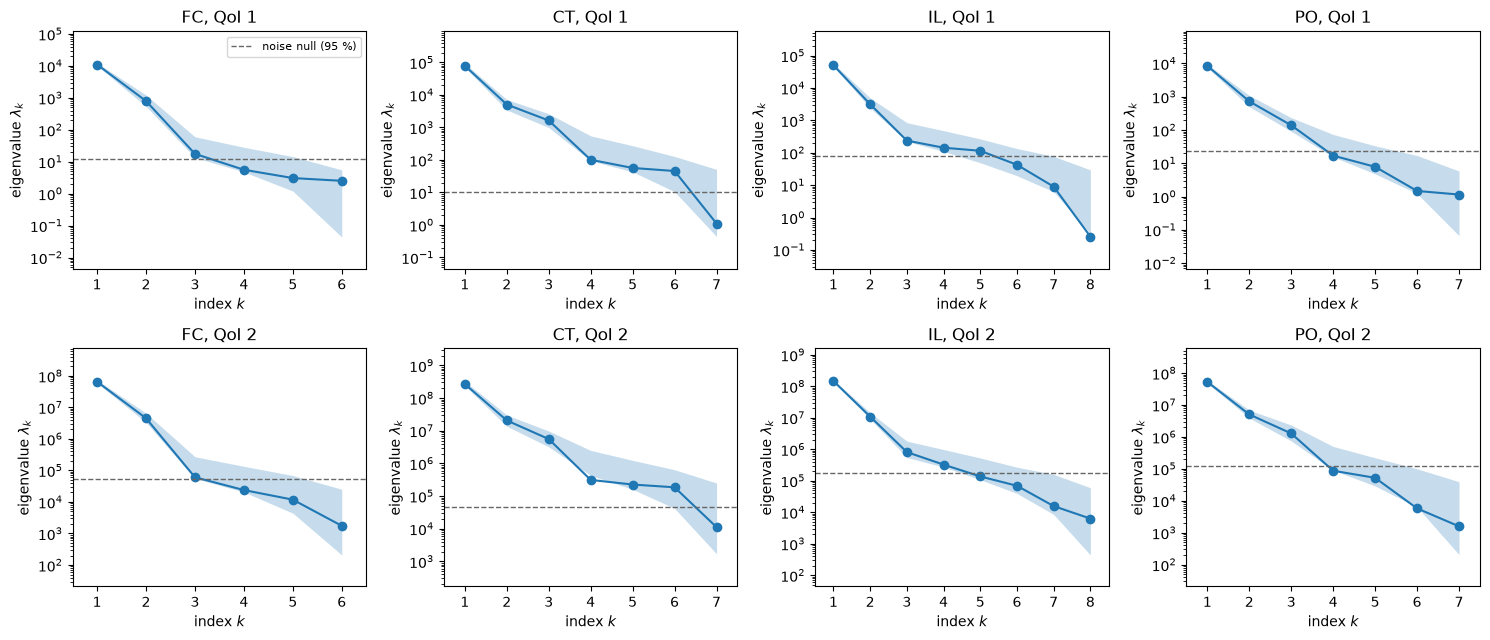

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, q in enumerate(QOIS):
    for j, s in enumerate(STRATS):
        ax = axes[i, j]
        ac.plotting.plot_eigenvalues(sub[s, q], interval='percentile', mark_dimension=False, ax=ax)
        ax.axhline(null95[s, q], color='0.4', ls='--', lw=1, label='noise null (95 %)')
        ax.set_title(f'{s}, QoI {i + 1}')
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

The figure shows the spectra (bootstrap 95 % bands) with the noise null as a dashed line. For every strategy and QoI the first two or three eigenvalues stand far above the null; CT and IL have further small eigenvalues above it. For FC the third eigenvalue sits at the null itself (ratio 1.6e-3 to $\lambda_1$ against a null of 1.1e-3 for $Q_1$, or 4.4e-4 to 1.8e-3 with the noise-share interval), so FC has a two-dimensional signal and nothing that this design can resolve beyond it.

QoI 1, peak 30-day mean IC prevalence (per million): bootstrap mean subspace distance for n = 1, 2, 3, 4
  FC: 0.026, 0.083, 0.546, 0.740
  CT: 0.041, 0.116, 0.199, 0.708
  IL: 0.045, 0.165, 0.674, 0.813
  PO: 0.046, 0.148, 0.253, 0.668
QoI 2, IC patient-days above capacity (per million): bootstrap mean subspace distance for n = 1, 2, 3, 4
  FC: 0.027, 0.087, 0.663, 0.770
  CT: 0.051, 0.125, 0.235, 0.731
  IL: 0.027, 0.100, 0.487, 0.625
  PO: 0.040, 0.144, 0.201, 0.679


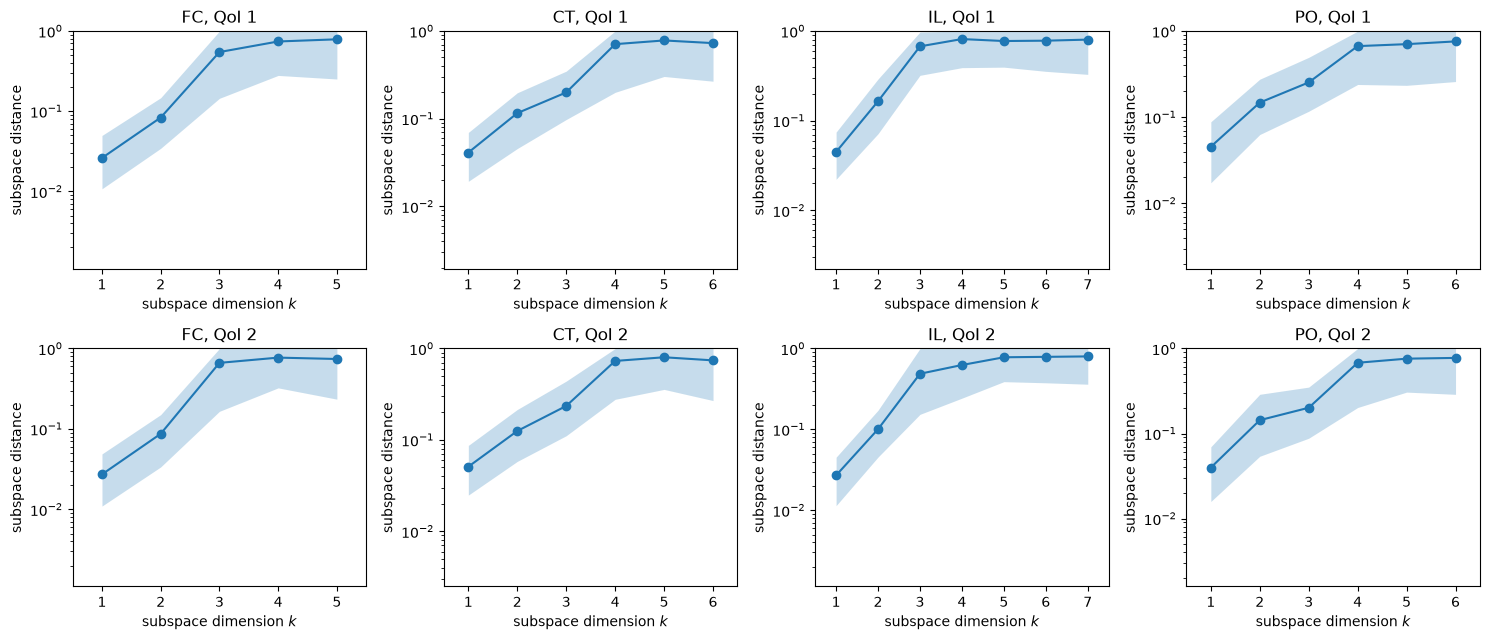

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, q in enumerate(QOIS):
    for j, s in enumerate(STRATS):
        ac.plotting.plot_subspace_errors(sub[s, q], interval='percentile', mark_dimension=False, ax=axes[i, j])
        axes[i, j].set_title(f'{s}, QoI {i + 1}')
fig.tight_layout()
plt.close(fig)
for q in QOIS:
    print(QLAB[q] + ': bootstrap mean subspace distance for n = 1, 2, 3, 4')
    for s in STRATS:
        d = sub[s, q].bootstrap_distances.mean(0)
        print(f'  {s}: {d[0]:.3f}, {d[1]:.3f}, {d[2]:.3f}, {d[3]:.3f}')
fig

The bootstrap subspace distances agree with the spectra. The one-dimensional subspace is the best determined everywhere (distance 0.026 to 0.051). The two-dimensional subspace is well determined for FC (0.083 and 0.087) and acceptable for the others (0.100 to 0.165). The three-dimensional one is unstable for FC and IL (0.487 to 0.674), whose third eigenvalue is close to the next, but not for CT and PO (0.199 to 0.253), where $\lambda_3/\lambda_4$ is large; their four-dimensional subspaces are unstable (0.668 to 0.731).

### Choosing the dimension

The leave-one-out $R^2$ of cubic and quartic polynomials in $n = 1, 2, 3$ active variables, of a degree-7 polynomial in $y_1$, of the full quadratic in all $m$ inputs, and the ceiling set by the seed noise:

In [10]:
def loo(s, q, n, degree=3):
    if n == 0:   # quadratic in all m inputs, for comparison
        return ac.fit_surrogate(X=Z[s], f=Y[s, q], space=sub[s, q].space, subspace=None,
                                kind='poly', degree=2).loo_r_squared
    return ac.fit_surrogate(X=Z[s], f=Y[s, q], subspace=ac.with_dimension(sub[s, q], n),
                            kind='poly', degree=degree).loo_r_squared

print(f"{'case':22s} {'cubic n=1':>9s} {'n=2':>6s} {'n=3':>6s}  {'quartic n=1':>11s} {'n=2':>6s} {'n=3':>6s}  "
      f"{'degree 7, n=1':>13s} {'quadratic, all m':>16s} {'R2 ceiling':>10s}")
LOO, LOO4, LOO7, LOOQ = {}, {}, {}, {}
for s in STRATS:
    for q in QOIS:
        LOO[s, q] = [loo(s, q, n) for n in (1, 2, 3)]
        LOO4[s, q] = [loo(s, q, n, degree=4) for n in (1, 2, 3)]
        LOO7[s, q] = loo(s, q, 1, degree=7)
        LOOQ[s, q] = loo(s, q, 0)
        ceil = 1 - noise[s, q]['share']
        print(f'{s} {q:18s} {LOO[s, q][0]:9.3f} {LOO[s, q][1]:6.3f} {LOO[s, q][2]:6.3f}  {LOO4[s, q][0]:11.3f} '
              f'{LOO4[s, q][1]:6.3f} {LOO4[s, q][2]:6.3f}  {LOO7[s, q]:13.3f} {LOOQ[s, q]:16.3f} {ceil:10.3f}')

case                   cubic n=1    n=2    n=3  quartic n=1    n=2    n=3  degree 7, n=1 quadratic, all m R2 ceiling
FC IC_prev_avg_max        0.931  0.972  0.972        0.937  0.978  0.979          0.937            0.948      0.985
FC IC_excess_days         0.917  0.964  0.965        0.931  0.977  0.975          0.935            0.944      0.988
CT IC_prev_avg_max        0.892  0.923  0.930        0.915  0.958  0.977          0.917            0.919      0.998
CT IC_excess_days         0.864  0.901  0.903        0.900  0.951  0.951          0.910            0.881      0.998
IL IC_prev_avg_max        0.901  0.925  0.920        0.908  0.946  0.949          0.908            0.909      0.985
IL IC_excess_days         0.942  0.973  0.974        0.942  0.979  0.981          0.943            0.946      0.987
PO IC_prev_avg_max        0.866  0.935  0.946        0.858  0.927  0.934          0.847            0.902      0.961
PO IC_excess_days         0.857  0.914  0.911        0.862  0.904  0.89

Two active variables reach the full quadratic's accuracy or exceed it everywhere (cubic in $n = 2$: 0.901 to 0.973; quadratic in all $m$: 0.881 to 0.948). For FC and IL a third variable changes either fit by at most 0.005 (IL, $Q_1$, cubic: 0.925 to 0.920). For CT the quartic gains most: for $Q_1$ it rises from 0.915 ($n = 1$) to 0.958 ($n = 2$) and 0.977 ($n = 3$), against a ceiling of 0.998, while the best one-dimensional fit (degree 7) reaches 0.917; for $Q_2$ it rises from 0.900 to 0.951 and stays at 0.951. For PO the third variable changes the cubic by +0.011 ($Q_1$: 0.935 to 0.946) and -0.003 ($Q_2$), and the quartic does not improve on the cubic (0.934 and 0.898 with $n = 3$). The gaps to the ceilings that remain are mostly structure the polynomials miss, chiefly the floor of $Q_2$ at zero and the bend where the epidemic stops being controlled (the summary plots below), not noise.

We use one rule for every strategy and both QoIs: **$n$ is the largest dimension for which $\lambda_n/\lambda_{n+1} \ge 8$ and the $n$-dimensional subspace is stable (mean bootstrap distance below 0.3).** The rule is not sensitive to these two thresholds here: in every case the distance is 0.253 or less at the chosen $n$ and 0.487 or more one dimension higher, and the ratio at the chosen $n$ (8.2 to 74.4) is followed by a ratio of 3.2 or less. It gives the same $n$ for both QoIs: $n = 2$ for FC and IL and $n = 3$ for CT and PO.

- **FC, n = 2.** $\lambda_2/\lambda_3$ is 45.1 and 74.4, $\lambda_3$ is at the noise null, and a third variable changes the cubic and quartic $R^2$ by 0.002 or less.
- **IL, n = 2.** $\lambda_2/\lambda_3$ is 13.3 and 13.4; $\lambda_3/\lambda_4$ is only 1.7 and 2.5, the three-dimensional subspace is unstable (0.674 and 0.487), and a third variable changes the fits by at most 0.005.
- **CT, n = 3.** $\lambda_1/\lambda_2$ is 15.5 and 13.0 and $\lambda_3/\lambda_4$ is 16.2 and 17.8, at least as large. $\lambda_2/\lambda_3$ is only 3.1 and 3.7, but $\mathbf w_2$ and $\mathbf w_3$ are not mixed up by the bootstrap: the two- and three-dimensional subspaces are both stable (0.116 and 0.125; 0.199 and 0.235), the two-dimensional one more so than those of IL ($Q_1$, 0.165) and PO (0.148 and 0.144). The left-out eigenvalue share falls from 0.0808 and 0.0912 ($n = 1$) to 0.0024 and 0.0025 ($n = 3$), the quartic $R^2$ rises from 0.915 to 0.977 ($Q_1$) and from 0.900 to 0.951 ($Q_2$), and a cubic in $y_3$ explains 0.247 and 0.178 of the variance left by the quartic in $(y_1, y_2)$ (figure below). The one-dimensional summary is still a good first description (cubic $R^2$ 0.892 and 0.864).
- **PO, n = 3.** The spectrum has CT's shape: $\lambda_2/\lambda_3$ is 5.2 and 3.9, $\lambda_3/\lambda_4$ is 8.2 and 14.7, and the three-dimensional subspace is stable (0.253 and 0.201). The gap of 8.2 for $Q_1$ is the weakest the rule accepts, and the third variable adds little to the fits (cubic +0.011 and -0.003), but a cubic in $y_3$ explains 0.106 and 0.178 of the variance left by the quartic in $(y_1, y_2)$, against 0.008 to 0.072 for FC and IL. $n = 2$ (cubic $R^2$ 0.935 and 0.914) is a close alternative for PO.

In [11]:
N_CHOSEN = {'FC': 2, 'CT': 3, 'IL': 2, 'PO': 3}
print('criterion: largest n with lambda_n/lambda_n+1 >= 8 and bootstrap subspace distance < 0.3')
for s in STRATS:
    for q in QOIS:
        n = N_CHOSEN[s]
        lam = sub[s, q].eigenvalues
        d = sub[s, q].bootstrap_distances.mean(0)
        ok = [k for k in range(1, 5) if lam[k - 1] / lam[k] >= 8 and d[k - 1] < 0.3]
        print(f'{s} {q:16s}: n = {n} (criterion gives {max(ok)}); '
              + ', '.join(f'n={k}: ratio {lam[k - 1] / lam[k]:.1f}, dist {d[k - 1]:.3f}' for k in range(1, 5)))
        print(f'{"":20s} left-out eigenvalue share for n = 1, 2, 3: '
              + ', '.join(f'{lam[k:].sum() / lam.sum():.4f}' for k in (1, 2, 3)) + '; '
              f'LOO R2 at n: cubic {LOO[s, q][n - 1]:.3f}, quartic {LOO4[s, q][n - 1]:.3f}')

# third direction: how much of the residual of a quartic in (y1, y2) does a cubic in y3 explain?
print('\nresidual of the quartic in (y1, y2): share of its variance explained by a cubic in y3')
RES3 = {}
for s in STRATS:
    out = []
    for q in QOIS:
        sur = ac.fit_surrogate(X=Z[s], f=Y[s, q], subspace=ac.with_dimension(sub[s, q], 2), kind='poly', degree=4)
        y3 = Z[s] @ sub[s, q].eigenvectors[:, 2]
        A = np.column_stack([y3 ** k for k in range(4)])
        e = sur.residuals - A @ np.linalg.lstsq(A, sur.residuals, rcond=None)[0]
        RES3[s, q] = (y3, sur.residuals)
        out.append(f'QoI {QOIS.index(q) + 1}: {1 - e.var() / sur.residuals.var():.3f} '
                   f'(residual variance / QoI variance {sur.residuals.var() / Y[s, q].var():.4f})')
    print(f'  {s}: ' + '; '.join(out))

criterion: largest n with lambda_n/lambda_n+1 >= 8 and bootstrap subspace distance < 0.3
FC IC_prev_avg_max : n = 2 (criterion gives 2); n=1: ratio 13.9, dist 0.026, n=2: ratio 45.1, dist 0.083, n=3: ratio 3.2, dist 0.546, n=4: ratio 1.8, dist 0.740
                     left-out eigenvalue share for n = 1, 2, 3: 0.0695, 0.0024, 0.0009; LOO R2 at n: cubic 0.972, quartic 0.978
FC IC_excess_days  : n = 2 (criterion gives 2); n=1: ratio 14.4, dist 0.027, n=2: ratio 74.4, dist 0.087, n=3: ratio 2.5, dist 0.663, n=4: ratio 2.0, dist 0.770
                     left-out eigenvalue share for n = 1, 2, 3: 0.0663, 0.0014, 0.0005; LOO R2 at n: cubic 0.964, quartic 0.977
CT IC_prev_avg_max : n = 3 (criterion gives 3); n=1: ratio 15.5, dist 0.041, n=2: ratio 3.1, dist 0.116, n=3: ratio 16.2, dist 0.199, n=4: ratio 1.8, dist 0.708
                     left-out eigenvalue share for n = 1, 2, 3: 0.0808, 0.0215, 0.0024; LOO R2 at n: cubic 0.930, quartic 0.977
CT IC_excess_days  : n = 3 (criterion gives 

The left-out eigenvalue share at the chosen $n$ is 0.0014 to 0.0101, and the cubic leave-one-out $R^2$ on the chosen subspaces is 0.903 to 0.973. The figure below plots the residuals of the quartic in $(y_1, y_2)$ against $y_3 = \mathbf w_3^T\mathbf z$. For CT they bend down at both ends of $y_3$ and for PO they fall along it; for FC and IL, whose $\mathbf w_3$ lies in the unresolved tail of the spectrum, they show no clear trend.

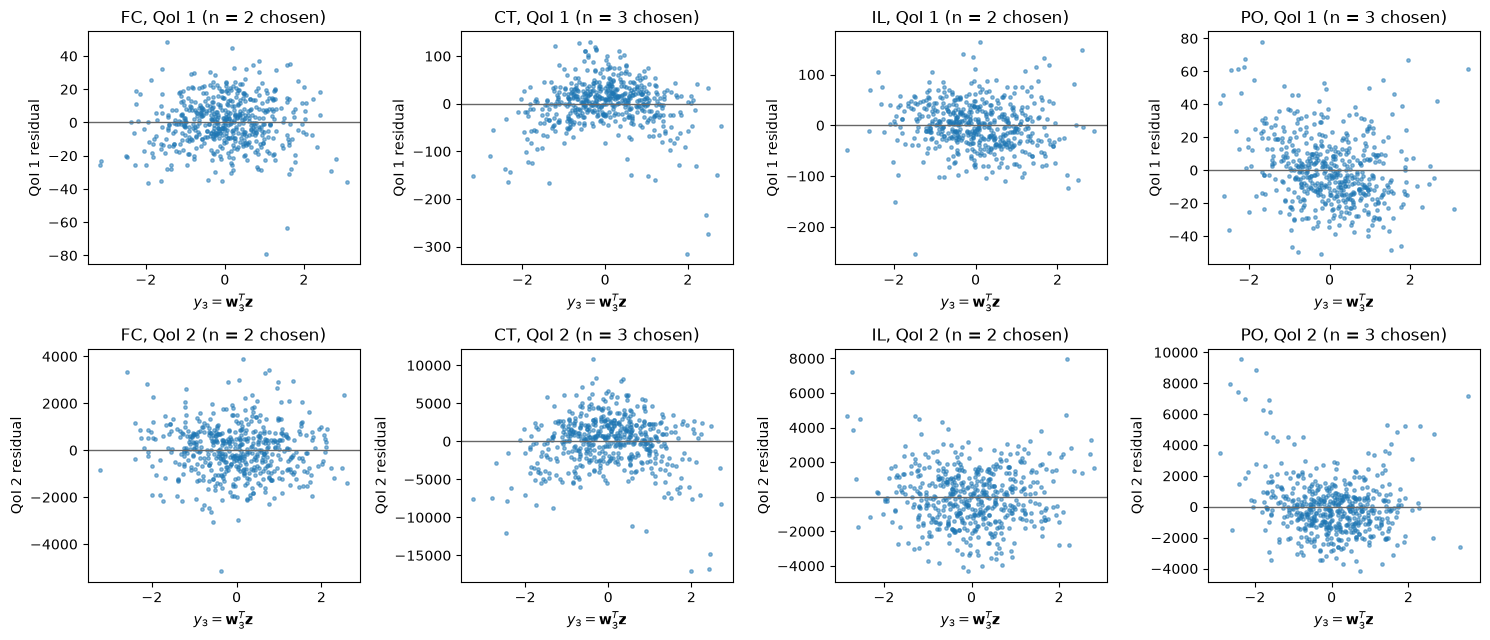

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, q in enumerate(QOIS):
    for j, s in enumerate(STRATS):
        y3, e = RES3[s, q]
        axes[i, j].scatter(y3, e, s=6, alpha=0.5)
        axes[i, j].axhline(0, color='0.4', lw=1)
        axes[i, j].set_xlabel(r'$y_3 = \mathbf{w}_3^T\mathbf{z}$')
        axes[i, j].set_ylabel(f'QoI {i + 1} residual')
        axes[i, j].set_title(f'{s}, QoI {i + 1} (n = {N_CHOSEN[s]} chosen)')
fig.tight_layout()
plt.close(fig)
fig

### Eigenvectors

The components of $\mathbf w_1$, $\mathbf w_2$ and $\mathbf w_3$ in the normal scores, for both QoIs, and the distance between the $Q_1$ and $Q_2$ subspaces of the chosen dimension:

In [13]:
print('eigenvectors (normalized coordinates z); w1: QoI increases along it, w2, w3: largest entry positive')
for s in STRATS:
    names = [SHORT[n] for n in INPUTS[s]]
    print(f'{s}: ' + ' '.join(f'{n:>11s}' for n in names))
    for q in QOIS:
        W = sub[s, q].eigenvectors
        for k in range(3):
            tag = '' if k < N_CHOSEN[s] else '   (outside the chosen subspace)'
            print(f'  QoI {QOIS.index(q) + 1} w{k + 1} ' + ' '.join(f'{v:11.3f}' for v in W[:, k]) + tag)
    n = N_CHOSEN[s]
    W1a, W1b = sub[s, QOIS[0]].eigenvectors[:, :n], sub[s, QOIS[1]].eigenvectors[:, :n]
    print(f'  distance between the QoI 1 and QoI 2 subspaces (n = {n}): '
          f'{np.linalg.norm(W1a @ W1a.T - W1b @ W1b.T, 2):.3f}')
E = np.eye(7)[:, :3]                                                # the three tracing inputs of CT
for q in QOIS:
    W3 = sub['CT', q].eigenvectors[:, :3]
    print(f'CT QoI {QOIS.index(q) + 1}: distance between the 3-D subspace and the span of the three tracing inputs '
          f'{np.linalg.norm(W3 @ W3.T - E @ E.T, 2):.3f}')

eigenvectors (normalized coordinates z); w1: QoI increases along it, w2, w3: largest entry positive
FC:     int_eff      uptake     dur_inf          R0 eff_var_inv     shape_E
  QoI 1 w1       0.635      -0.520      -0.052       0.566      -0.044       0.038
  QoI 1 w2       0.558       0.812      -0.103       0.100      -0.047       0.082
  QoI 1 w3      -0.410       0.147      -0.560       0.563       0.388       0.173   (outside the chosen subspace)
  QoI 2 w1       0.606      -0.558      -0.015       0.562      -0.057       0.044
  QoI 2 w2       0.585       0.790      -0.080       0.142      -0.017       0.084
  QoI 2 w3      -0.198       0.031       0.171       0.178       0.031       0.948   (outside the chosen subspace)
  distance between the QoI 1 and QoI 2 subspaces (n = 2): 0.046
CT:   tr_rate_I   tr_prob_E      tr_red     dur_inf          R0 eff_var_inv     shape_E
  QoI 1 w1      -0.787      -0.306      -0.425      -0.185       0.268       0.008       0.018
  QoI 1 w2     

**FC**: $\mathbf w_1$ for $Q_1$ weights `intervention_effect` 0.635, $R_0$ 0.566 and `uptake` -0.520, with every other component below 0.06 in magnitude: the peak rises with the transmission the measures allow and with $R_0$, and falls with uptake. $\mathbf w_2$ is mostly `uptake` (0.812 in magnitude) and `intervention_effect` (0.558). **CT**: $\mathbf w_1$ is led by `trace_rate_I` (-0.787), then `trace_contact_reduction` (-0.425), `trace_prob_E` (-0.306), $R_0$ (0.268) and `avg_duration_infectiousness` (-0.185): faster and more effective tracing lowers the peak. $\mathbf w_2$ is mostly `trace_contact_reduction` (0.881) and $\mathbf w_3$ mostly `trace_prob_E` (0.889), each mixed with `trace_rate_I` (-0.414 and -0.394), so the three-dimensional subspace lies close to the span of the three tracing inputs (distance 0.363 for $Q_1$; $R_0$ and `avg_duration_infectiousness` enter through $\mathbf w_1$). The paper singles out the interaction between `trace_prob_E` and `trace_rate_I` as the main second-order effect in CT, from the difference between total and first-order indices (p. 14, S3 Fig). **IL**: $\mathbf w_1$ is `uptake` (-0.687) against $R_0$ (0.674), with `lock_effect` at 0.182; $\mathbf w_2$ is led by `lock_effect` (0.723), `lock_length` and `lift_length` (0.410 and 0.384 in magnitude). **PO**: $\mathbf w_1$ is `uptake` (-0.679), `pl_intervention_effect_hi` (0.549) and $R_0$ (0.464); $\mathbf w_2$ mixes `pl_intervention_effect_hi` (0.652), `uptake` (0.643) and `intervention_lift_interval` (-0.381), and $\mathbf w_3$ is mostly `intervention_lift_interval` (0.862). The distance between the $Q_1$ and $Q_2$ subspaces of the chosen dimension is 0.046 (FC), 0.067 (CT), 0.259 (IL) and 0.175 (PO).

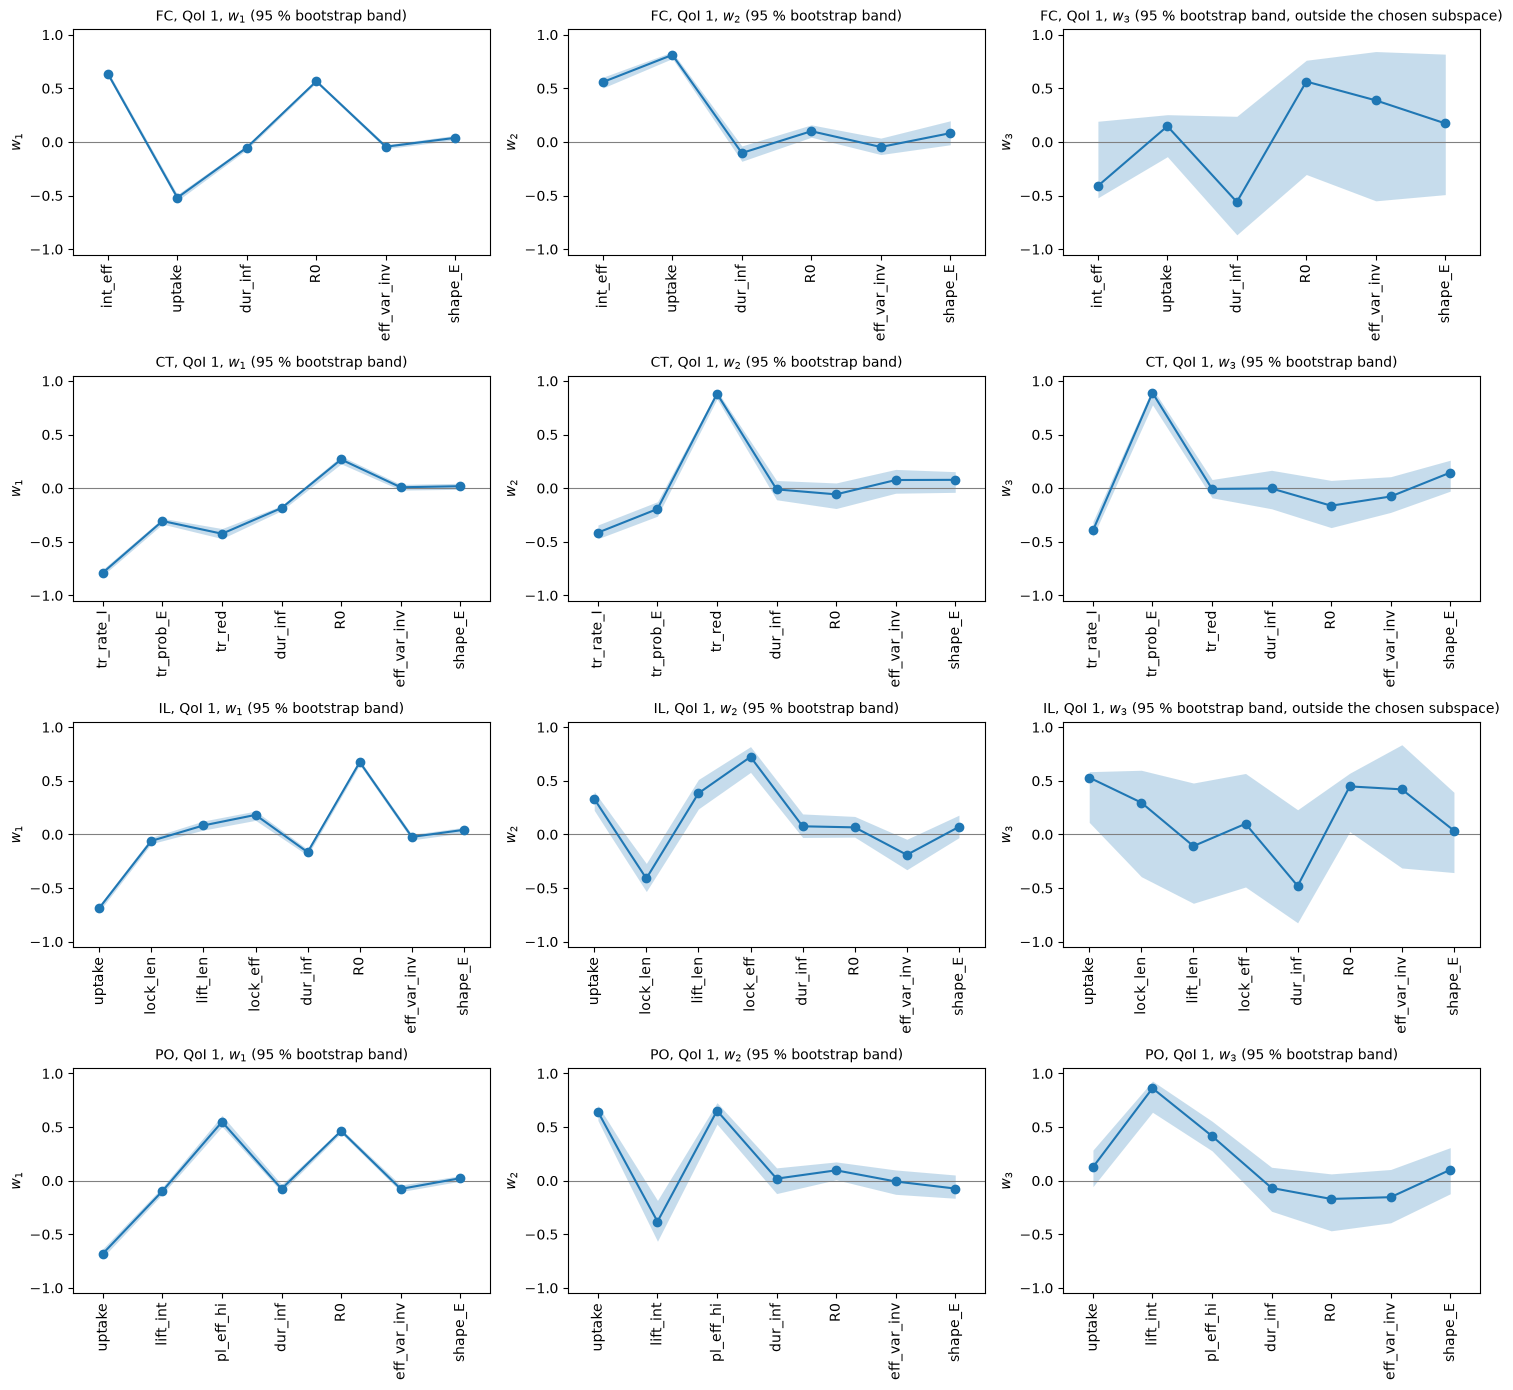

In [14]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for i, s in enumerate(STRATS):
    for k in range(3):
        ac.plotting.plot_eigenvectors(sub[s, QOIS[0]], indices=[k], labels=[SHORT[n] for n in INPUTS[s]],
                                      interval='percentile', ax=[axes[i, k]])
        extra = '' if k < N_CHOSEN[s] else ', outside the chosen subspace'
        axes[i, k].set_title(f'{s}, QoI 1, $w_{k + 1}$ (95 % bootstrap band{extra})', fontsize=10)
fig.tight_layout()
plt.close(fig)
fig

The bands are the 95 % bootstrap percentile intervals of each component. They are narrow for $\mathbf w_1$ everywhere and wider for $\mathbf w_2$, whose policy components are still clearly away from 0; its non-policy components are at most 0.190 in magnitude (IL, `intervention_effect_var_inv`). $\mathbf w_3$ is well determined only where it belongs to the chosen subspace (CT and PO); for FC and IL it lies in the tail of the spectrum, its bands are wide, and the library flags its bootstrap replicates as poorly aligned (printed with the estimate). Three non-policy inputs, `avg_duration_infectiousness`, `intervention_effect_var_inv` and `shape_exposed_time`, matter little for every strategy, while $R_0$ is a leading input of FC, IL and PO.

In [15]:
print('normalized activity scores alpha_i(n) / sum_i alpha_i(n), QoI 1, at the chosen n')
for s in STRATS:
    a = ac.activity_scores(sub[s, QOIS[0]], n=N_CHOSEN[s])
    a = a / a.sum()
    order = np.argsort(-a)
    print(f'  {s} (n = {N_CHOSEN[s]}): ' + ', '.join(f'{INPUTS[s][k]} {a[k]:.3f}' for k in order))

normalized activity scores alpha_i(n) / sum_i alpha_i(n), QoI 1, at the chosen n
  FC (n = 2): intervention_effect 0.397, R0 0.299, uptake 0.296, avg_duration_infectiousness 0.003, intervention_effect_var_inv 0.002, shape_exposed_time 0.002
  CT (n = 3): trace_rate_I 0.584, trace_contact_reduction 0.212, trace_prob_E 0.104, R0 0.067, avg_duration_infectiousness 0.032, shape_exposed_time 0.001, intervention_effect_var_inv 0.001
  IL (n = 2): uptake 0.450, R0 0.428, lock_effect 0.062, avg_duration_infectiousness 0.026, lift_length 0.015, lock_length 0.013, intervention_effect_var_inv 0.003, shape_exposed_time 0.002
  PO (n = 3): uptake 0.451, pl_intervention_effect_hi 0.309, R0 0.197, intervention_lift_interval 0.031, intervention_effect_var_inv 0.006, avg_duration_infectiousness 0.005, shape_exposed_time 0.001


The activity scores at the chosen $n$, normalized to sum to 1, rank the inputs: FC `intervention_effect` 0.397, $R_0$ 0.299, `uptake` 0.296; CT `trace_rate_I` 0.584, `trace_contact_reduction` 0.212, `trace_prob_E` 0.104; IL `uptake` 0.450, $R_0$ 0.428, `lock_effect` 0.062; PO `uptake` 0.451, `pl_intervention_effect_hi` 0.309, $R_0$ 0.197. The lockdown and lift lengths of IL (0.013 and 0.015) and the lift interval of PO (0.031) are minor.

### Sufficient summary plots

Top row: $Q_1$ against $y_1 = \mathbf w_1^T\mathbf z$, with the IC capacity of 109 per million dashed. Bottom row: $(y_1, y_2)$ coloured by $Q_1$; for CT and PO, where $n = 3$ is chosen, $y_3$ is not shown (its effect is in the residual figure above).

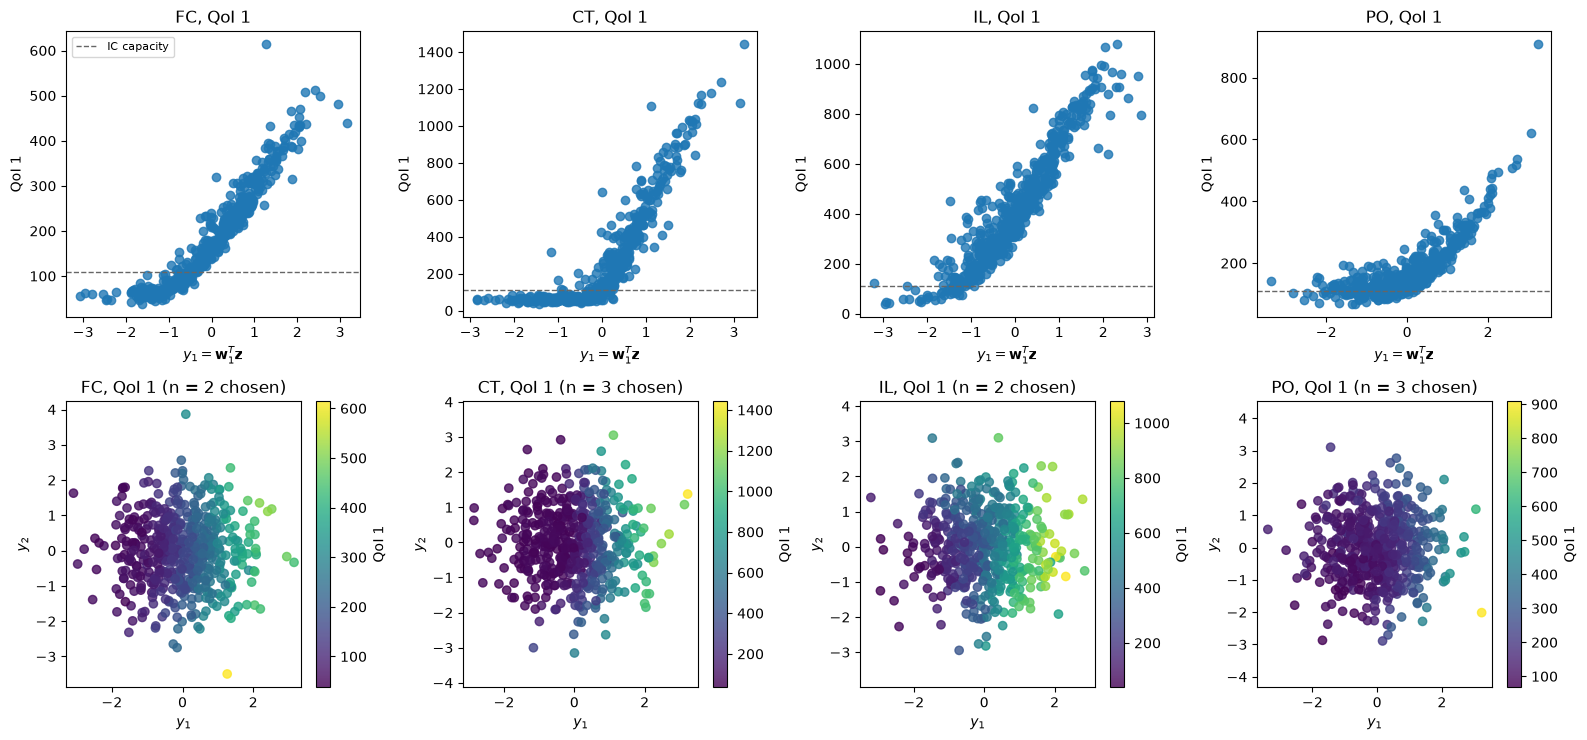

In [16]:
q = QOIS[0]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for j, s in enumerate(STRATS):
    ac.plotting.plot_sufficient_summary(sub[s, q], X=Z[s], f=Y[s, q], dims=1, ax=axes[0, j], qoi_label='QoI 1')
    axes[0, j].set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{z}$')
    axes[0, j].axhline(IC_CAPACITY, color='0.4', ls='--', lw=1, label='IC capacity')
    axes[0, j].set_title(f'{s}, QoI 1')
    ac.plotting.plot_sufficient_summary(sub[s, q], X=Z[s], f=Y[s, q], dims=2, ax=axes[1, j], qoi_label='QoI 1')
    axes[1, j].set_title(f'{s}, QoI 1 (n = {N_CHOSEN[s]} chosen)')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

$Q_1$ increases with $y_1$ for every strategy, with a floor on the low side, a bend, and a small scatter around the trend. For FC and IL the rise above the floor is close to linear (IL flattens slightly at the top); for CT and PO the curve is nearly flat on the low side (peaks below about 150 per million) and bends up sharply once the epidemic escapes control, a shape that a cubic follows only approximately and that limits the one-dimensional $R^2$. In the bottom row the colour changes mainly along $y_1$; for FC, IL and PO the contours are tilted, which is the second direction. A fraction 0.299 (FC), 0.461 (CT), 0.059 (IL) and 0.166 (PO) of the main runs keeps $Q_1$ at or below the IC capacity.

PO main runs whose QoI 1 peak is on the last day the centred average covers (day 535): 2; within its last 30 days: 4; largest daily prevalence on day 550, all PO runs: 164 per million (FC, CT, IL: at most 33)


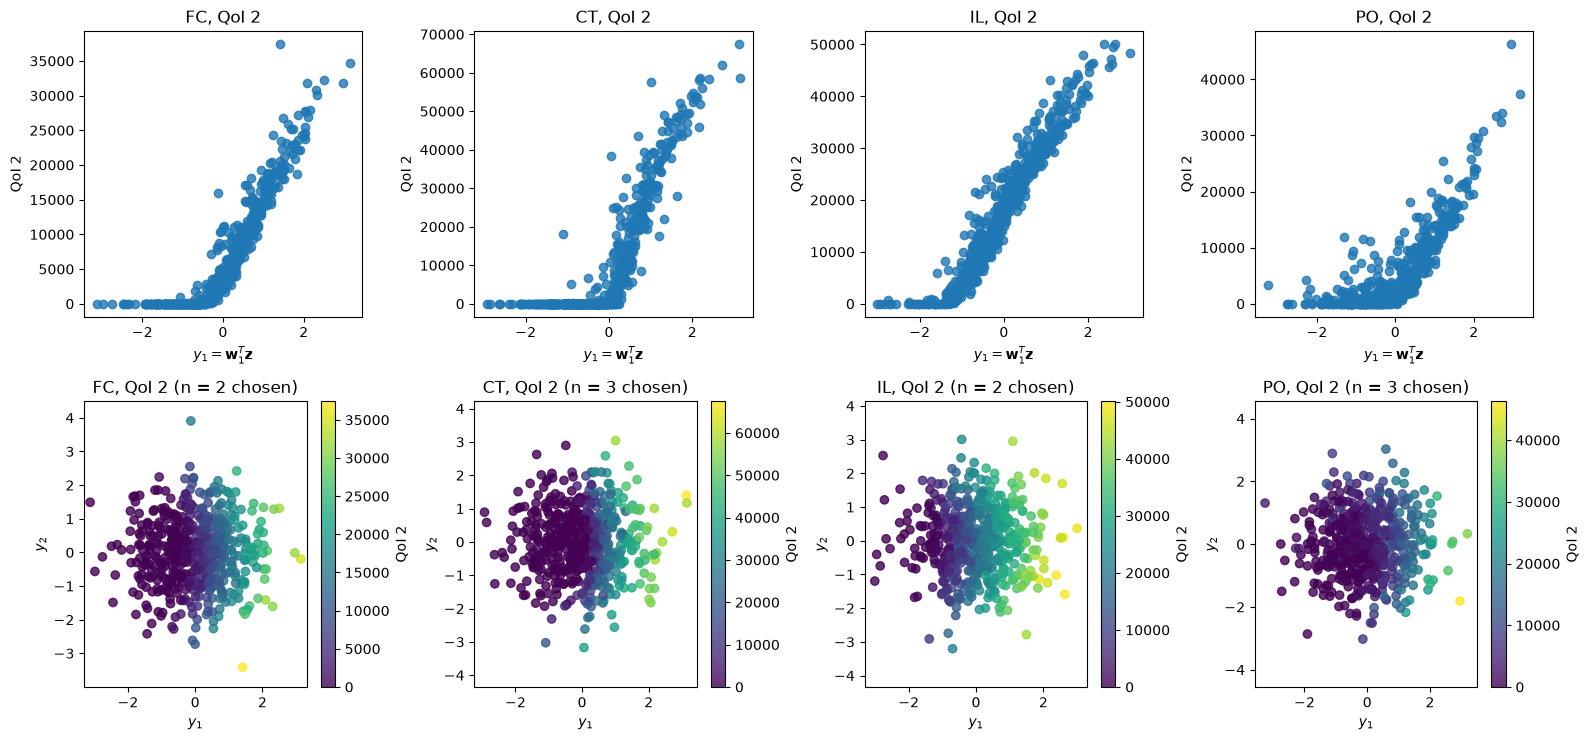

In [17]:
q = QOIS[1]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for j, s in enumerate(STRATS):
    ac.plotting.plot_sufficient_summary(sub[s, q], X=Z[s], f=Y[s, q], dims=1, ax=axes[0, j], qoi_label='QoI 2')
    axes[0, j].set_xlabel(r'$y_1 = \mathbf{w}_1^T\mathbf{z}$')
    axes[0, j].set_title(f'{s}, QoI 2')
    ac.plotting.plot_sufficient_summary(sub[s, q], X=Z[s], f=Y[s, q], dims=2, ax=axes[1, j], qoi_label='QoI 2')
    axes[1, j].set_title(f'{s}, QoI 2 (n = {N_CHOSEN[s]} chosen)')
fig.tight_layout()
plt.close(fig)

# PO runs whose averaged peak falls at the end of the 550 days
w = np.r_[0.5, np.ones(29), 0.5] / 30
ma = np.array([np.convolve(t, w, mode='valid') for t in ic_prev['PO'][:, 1:]])   # centred on days 15..535
last = ma.argmax(1)
mainPO = runs['PO'][:, col('PO', 'kind')] == 0
print(f'PO main runs whose QoI 1 peak is on the last day the centred average covers (day {ma.shape[1] + 14}): '
      f'{np.sum((last == ma.shape[1] - 1) & mainPO)}; within its last 30 days: {np.sum((last >= ma.shape[1] - 30) & mainPO)}; '
      f'largest daily prevalence on day 550, all PO runs: {ic_prev["PO"][:, -1].max():.0f} per million '
      f'(FC, CT, IL: at most {max(ic_prev[s][:, -1].max() for s in ["FC", "CT", "IL"]):.0f})')
fig

$Q_2$ has the same structure, with a floor at zero (no overload) on the low side of $y_1$: 26.2 % of the FC runs and 43.8 % of the CT runs sit on it. Above the floor $Q_2$ grows roughly linearly in $y_1$ (PO more steeply at the top). The floor is one reason why $Q_2$'s leave-one-out $R^2$ for CT (cubic, $n = 3$: 0.903) is lower than $Q_1$'s (0.930). In 2 PO main runs the averaged peak falls on the last day the centred average covers (day 535), and in 4 within its last 30 days: in some PO runs the epidemic is still under way at the end of the 550 days (up to 164 IC patients per million on day 550, against at most 33 for the other strategies). The 550-day horizon is the paper's (p. 5), so these QoIs are cut off by it as they would be in the paper's runs.

### Checks: the linear direction and the whole days

The QPHD matrix contains $\mathbf g\mathbf g^T$, the outer product of the linear part of the fit; when it dominates, $\mathbf w_1$ is the least-squares (OLS) direction. We also redo the estimate with the IL and PO durations replaced by the whole days that virsim used, at the middle of each day, $z = \Phi^{-1}(F(d + \tfrac12))$.

In [18]:
print('global linear model (OLS) direction vs w1 (|cosine|), and the share of variance it explains')
for s in STRATS:
    for q in QOIS:
        o = ac.active_subspace(space=sub[s, q].space, X=Z[s], f=Y[s, q], estimator='ols', n=1)
        A = np.column_stack([np.ones(len(Z[s])), Z[s]])
        res = Y[s, q] - A @ np.linalg.lstsq(A, Y[s, q], rcond=None)[0]
        print(f'  {s} QoI {QOIS.index(q) + 1}: |cos(w_OLS, w1)| = {abs(o.eigenvectors[:, 0] @ sub[s, q].eigenvectors[:, 0]):.3f}, '
              f'linear R2 = {1 - res.var() / Y[s, q].var():.3f}')
print('\nwhole days: inputs replaced by the days virsim used, z = Phi^-1(F(d + 1/2))')
for s, pairs in [('IL', [('lock_days', 'lock_length'), ('lift_days', 'lift_length')]),
                 ('PO', [('lift_interval_days', 'intervention_lift_interval')])]:
    R = runs[s][runs[s][:, col(s, 'kind')] == 0]
    Zd = Z[s].copy()
    for a, b in pairs:
        j = INPUTS[s].index(b)
        Zd[:, j] = stats.norm.ppf(TABLE1[b][0].cdf(R[:, col(s, a)] + 0.5))
    n = N_CHOSEN[s]
    for q in QOIS:
        r = ac.active_subspace(space=sub[s, q].space, X=Zd, f=Y[s, q], estimator='qphd', n=n)
        W1, Wd = sub[s, q].eigenvectors[:, :n], r.eigenvectors[:, :n]
        print(f'  {s} QoI {QOIS.index(q) + 1}: distance to the subspace from the design values (n = {n}) '
              f'{np.linalg.norm(W1 @ W1.T - Wd @ Wd.T, 2):.3f}; '
              f'max |z_days - z_design| = {np.abs(Zd - Z[s]).max():.3f}')

global linear model (OLS) direction vs w1 (|cosine|), and the share of variance it explains
  FC QoI 1: |cos(w_OLS, w1)| = 1.000, linear R2 = 0.874
  FC QoI 2: |cos(w_OLS, w1)| = 1.000, linear R2 = 0.793
  CT QoI 1: |cos(w_OLS, w1)| = 1.000, linear R2 = 0.723
  CT QoI 2: |cos(w_OLS, w1)| = 1.000, linear R2 = 0.709
  IL QoI 1: |cos(w_OLS, w1)| = 0.998, linear R2 = 0.871
  IL QoI 2: |cos(w_OLS, w1)| = 1.000, linear R2 = 0.909
  PO QoI 1: |cos(w_OLS, w1)| = 0.988, linear R2 = 0.646
  PO QoI 2: |cos(w_OLS, w1)| = 0.991, linear R2 = 0.661

whole days: inputs replaced by the days virsim used, z = Phi^-1(F(d + 1/2))
  IL QoI 1: distance to the subspace from the design values (n = 2) 0.008; max |z_days - z_design| = 0.170
  IL QoI 2: distance to the subspace from the design values (n = 2) 0.011; max |z_days - z_design| = 0.170
  PO QoI 1: distance to the subspace from the design values (n = 3) 0.009; max |z_days - z_design| = 0.075
  PO QoI 2: distance to the subspace from the design values (n

$\mathbf w_1$ is the OLS direction to a cosine of 0.988 or more: the dominant direction is a global linear trend, which explains 0.646 (PO, $Q_1$) to 0.909 (IL, $Q_2$) of the variance; QPHD adds the second direction from the curvature. Replacing the IL and PO durations by the days virsim used moves the normal scores by at most 0.170 and the chosen subspaces by a distance of 0.011 or less, so treating these inputs as continuous does not change the result.

### Comparison with the paper

The paper estimates first-order Sobol' indices for $Q_1$ (Fig. 3, p. 13) by Saltelli's method with $M = 2000$, varying only the policy inputs and the seed, with the non-policy inputs fixed (p. 10). Our design varies all $m$ inputs, so its indices are smaller for the policy inputs by construction. As a rough comparison we estimate first-order effects from the main design by binning each input into 16 equal-probability bins, and rescale each policy effect by one minus the sum of the non-policy effects, an approximate policy-only level (exact only for an additive function):

In [19]:
print('first-order effects, QoI 1: variance of the mean of QoI 1 over 16 equal-probability bins of '
      'each input, divided by the variance of QoI 1 (all m inputs varied)')
S1B = {}
for s in STRATS:
    y = Y[s, QOIS[0]]
    S1 = []
    for j in range(len(INPUTS[s])):
        b = np.minimum((U[s][:, j] * 16).astype(int), 15)
        mu = np.array([y[b == k].mean() for k in range(16)])
        cnt = np.bincount(b, minlength=16)
        S1.append(np.sum(cnt * (mu - y.mean()) ** 2) / len(y) / y.var())
    S1B[s] = dict(zip(INPUTS[s], S1))
    order = np.argsort(S1)[::-1]
    print(f'  {s}: ' + ', '.join(f'{INPUTS[s][k]} {S1[k]:.2f}' for k in order) +
          f'; seed (noise share) {noise[s, QOIS[0]]["share"]:.3f}')
print(f'  (bias of a 16-bin estimate from M = 512 independent points: about {15 / 512:.3f})')

print('\npolicy effects rescaled to the policy-only setting: S_i / (1 - sum of the non-policy effects)')
for s in STRATS:
    rest = 1 - sum(S1B[s][n] for n in COMMON)
    pol = [n for n in INPUTS[s] if n not in COMMON]
    print(f'  {s}: 1 - non-policy sum = {rest:.2f}; ' + ', '.join(f'{n} {S1B[s][n] / rest:.2f}' for n in pol))
print('\nsd of QoI 1 with the first-order effect of R0 removed, relative change 1 - sqrt(1 - S_R0):')
print('  ' + ', '.join(f'{s} {1 - np.sqrt(1 - S1B[s]["R0"]):.2f}' for s in STRATS))

first-order effects, QoI 1: variance of the mean of QoI 1 over 16 equal-probability bins of each input, divided by the variance of QoI 1 (all m inputs varied)
  FC: intervention_effect 0.36, R0 0.28, uptake 0.26, intervention_effect_var_inv 0.00, avg_duration_infectiousness 0.00, shape_exposed_time 0.00; seed (noise share) 0.015
  CT: trace_rate_I 0.54, trace_contact_reduction 0.17, trace_prob_E 0.07, R0 0.05, avg_duration_infectiousness 0.03, shape_exposed_time 0.00, intervention_effect_var_inv 0.00; seed (noise share) 0.002
  IL: uptake 0.43, R0 0.39, lock_effect 0.05, avg_duration_infectiousness 0.02, lift_length 0.01, lock_length 0.01, shape_exposed_time 0.00, intervention_effect_var_inv 0.00; seed (noise share) 0.015
  PO: uptake 0.30, pl_intervention_effect_hi 0.27, R0 0.16, intervention_lift_interval 0.03, avg_duration_infectiousness 0.01, intervention_effect_var_inv 0.01, shape_exposed_time 0.00; seed (noise share) 0.039
  (bias of a 16-bin estimate from M = 512 independent poi

The paper's uncertainty analysis (Fig. 2, top row, p. 12) varies all Table 1 inputs and the seed, as this design does, with 2000 Monte Carlo runs (p. 10), so its empirical CDFs are the published result most directly comparable with these data. We read seven points per strategy from the published figure ($Q_1 \le$ 80, 109, 200 and 300; $Q_2 \le$ 1, 1000 and 10000, where 1 is the left end of its axis), with a reading uncertainty of about $\pm 0.02$, and plot our empirical CDFs with their 95 % Dvoretzky-Kiefer-Wolfowitz band, the band the paper also draws (p. 11):

95 % DKW band of the empirical CDFs here: +-0.060 (M = 512); the paper's M = 2000: +-0.030
     Q1<=80     Q1<=109    Q1<=200    Q1<=300    Q2<=1      Q2<=1000   Q2<=10000 
FC here     0.180     0.299     0.582     0.840     0.264     0.369     0.697
FC Fig2      0.20      0.33      0.63      0.86      0.29      0.40      0.73   largest |difference| 0.048
CT here     0.393     0.461     0.562     0.666     0.441     0.492     0.615
CT Fig2      0.36      0.43      0.55      0.64      0.41      0.46      0.59   largest |difference| 0.033
IL here     0.035     0.059     0.172     0.338     0.045     0.092     0.289
IL Fig2      0.03      0.06      0.17      0.33      0.05      0.08      0.28   largest |difference| 0.012
PO here     0.012     0.166     0.717     0.912     0.094     0.318     0.777
PO Fig2      0.02      0.17      0.73      0.93      0.10      0.34      0.79   largest |difference| 0.022



notebook run time: 17 s


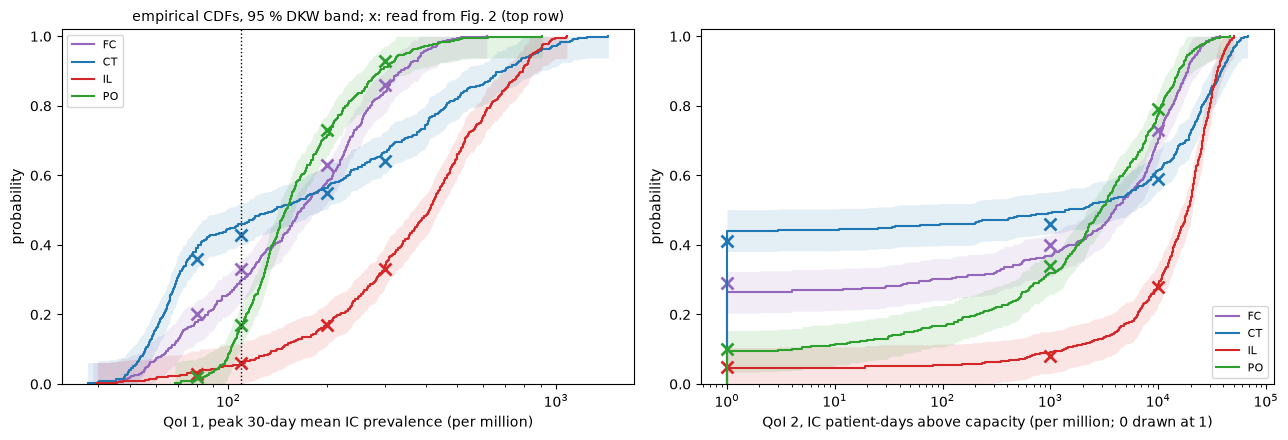

In [20]:
# Values read from the paper's Fig. 2, top row (p. 12), by digitizing the published figure (reading
# uncertainty about +-0.02 in probability). Keys: P(QoI 1 <= x) for x = 80, 109, 200, 300; P(QoI 2 <= x) for x = 1, 1000, 10000.
FIG2_READ = {
    'FC': {('Q1', 80): 0.20, ('Q1', 109): 0.33, ('Q1', 200): 0.63, ('Q1', 300): 0.86,
           ('Q2', 1): 0.29, ('Q2', 1000): 0.40, ('Q2', 10000): 0.73},
    'CT': {('Q1', 80): 0.36, ('Q1', 109): 0.43, ('Q1', 200): 0.55, ('Q1', 300): 0.64,
           ('Q2', 1): 0.41, ('Q2', 1000): 0.46, ('Q2', 10000): 0.59},
    'IL': {('Q1', 80): 0.03, ('Q1', 109): 0.06, ('Q1', 200): 0.17, ('Q1', 300): 0.33,
           ('Q2', 1): 0.05, ('Q2', 1000): 0.08, ('Q2', 10000): 0.28},
    'PO': {('Q1', 80): 0.02, ('Q1', 109): 0.17, ('Q1', 200): 0.73, ('Q1', 300): 0.93,
           ('Q2', 1): 0.10, ('Q2', 1000): 0.34, ('Q2', 10000): 0.79},
}
DKW = np.sqrt(np.log(2 / 0.05) / (2 * 512))           # 95 % Dvoretzky-Kiefer-Wolfowitz band, M = 512
print(f'95 % DKW band of the empirical CDFs here: +-{DKW:.3f} (M = 512); the paper\'s M = 2000: '
      f'+-{np.sqrt(np.log(2 / 0.05) / (2 * 2000)):.3f}')
print(f"{'':4s} " + ' '.join(f'{k[0]}<={k[1]:<6g}' for k in FIG2_READ['FC']))
for s in STRATS:
    here = {k: np.mean(Y[s, QOIS[0] if k[0] == 'Q1' else QOIS[1]] <= k[1]) for k in FIG2_READ[s]}
    print(f'{s} here ' + ' '.join(f'{here[k]:9.3f}' for k in FIG2_READ[s]))
    print(f'{s} Fig2 ' + ' '.join(f'{FIG2_READ[s][k]:9.2f}' for k in FIG2_READ[s]) +
          f'   largest |difference| {max(abs(here[k] - FIG2_READ[s][k]) for k in here):.3f}')

colors = dict(zip(STRATS, ['C4', 'C0', 'C3', 'C2']))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i, q in enumerate(QOIS):
    ax = axes[i]
    for s in STRATS:
        y = np.sort(np.maximum(Y[s, q], 1.0) if i == 1 else Y[s, q])
        p = np.arange(1, len(y) + 1) / len(y)
        ax.step(y, p, where='post', color=colors[s], lw=1.5, label=s)
        ax.fill_between(y, np.clip(p - DKW, 0, 1), np.clip(p + DKW, 0, 1), step='post', color=colors[s], alpha=0.12, lw=0)
        pts = [(k[1], v) for k, v in FIG2_READ[s].items() if k[0] == f'Q{i + 1}']
        ax.plot(*zip(*pts), 'x', color=colors[s], ms=8, mew=2)
    ax.set_xscale('log')
    ax.set_ylim(0, 1.02)
    ax.set_ylabel('probability')
    if i == 0:
        ax.axvline(IC_CAPACITY, color='k', ls=':', lw=1)
        ax.set_xlabel('QoI 1, peak 30-day mean IC prevalence (per million)')
    else:
        ax.set_xlabel('QoI 2, IC patient-days above capacity (per million; 0 drawn at 1)')
    ax.legend(fontsize=8, loc='upper left' if i == 0 else 'lower right')
axes[0].set_title('empirical CDFs, 95 % DKW band; x: read from Fig. 2 (top row)', fontsize=10)
fig.tight_layout()
plt.close(fig)
print(f'\nnotebook run time: {time.perf_counter() - t_start:.0f} s')
fig

The binned first-order effects rank the policy inputs as the paper does: FC `intervention_effect` 0.36 above `uptake` 0.26, CT `trace_rate_I` 0.54 then `trace_contact_reduction` 0.17, IL `uptake` 0.43 far above `lock_effect` 0.05, PO `uptake` 0.30 next to `pl_intervention_effect_hi` 0.27. Rescaled to the policy-only setting they come close to the levels on p. 13: IL `uptake` 0.74 ("about 70%"), CT `trace_rate_I` 0.58 ("circa 50%"), `uptake` 0.37 in FC and PO ("at least 30%"), FC `intervention_effect` 0.50 above `uptake`, PO `uptake` 0.37 and `pl_intervention_effect_hi` 0.33 ("similar importance"). This agreement is approximate: the rescaling assumes an additive function, and a 16-bin estimate from 512 independent points would carry an upward bias of about 0.029 (the inputs without effect print 0.00 here).

The empirical CDFs agree with the values read from Fig. 2 to within 0.048 (FC), 0.033 (CT), 0.012 (IL) and 0.022 (PO), inside our DKW band of $\pm 0.060$. $P(Q_1 \le 109)$ is 0.299, 0.461, 0.059 and 0.166 here, against about 0.33, 0.43, 0.06 and 0.17 in the figure, and $P(Q_2 \le 1)$ is 0.264, 0.441, 0.045 and 0.094, against about 0.29, 0.41, 0.05 and 0.10. FC lies below the figure at all seven points (by up to 0.048); errors of an empirical CDF at neighbouring points are correlated, so a shift of the whole curve of this size is within sampling error.

The main difference is $R_0$. The paper's uncertainty analysis varies it (Table 1, p. 4; Fig. 2, top row), but its sensitivity analysis holds it fixed (p. 10). Here it has a first-order effect of 0.28 (FC), 0.39 (IL) and 0.16 (PO) and a leading component in $\mathbf w_1$. The paper judged the CDFs "only weakly affected by non-policy-related parameters" (p. 12), comparing the top and bottom rows of Fig. 2. Removing the first-order effect of $R_0$ would lower the sd of $Q_1$ by a fraction 0.15 (FC), 0.22 (IL) and 0.09 (PO), a modest shift on the log axis of Fig. 2, so the weight of $R_0$ here goes beyond the scope of the paper's sensitivity analysis rather than contradicting its uncertainty analysis.

| quantity | paper (page) | this notebook |
|---|---|---|
| active subspace | not reported (no subspace analysis) | $\lambda_1/\lambda_2$ = 13.9, 15.5, 16.0, 11.7 ($Q_1$: FC, CT, IL, PO); $n$ = 2, 3, 2, 3 |
| FC: most important input | `intervention_effect`, Sobol' index above that of `uptake` (p. 13) | `intervention_effect` 0.36, `uptake` 0.26 (binned); activity 0.397 and 0.296 |
| uptake share in FC, IL, PO | "at least 30%" of the variance; IL "about 70%" (p. 13; policy inputs only) | 0.26, 0.43, 0.30 (binned, all inputs varied); 0.37, 0.74, 0.37 rescaled to policy only |
| CT: `trace_rate_I` | "circa 50%" of the variance (p. 13) | 0.54 (binned), 0.58 rescaled; activity score 0.584 |
| PO: `uptake` vs `pl_intervention_effect_hi` | "similar importance" (p. 13) | 0.30 and 0.27 (binned); 0.37 and 0.33 rescaled |
| `trace_prob_E`, `intervention_lift_interval`, IL lengths | "only a small contribution" (pp. 13-14) | 0.07, 0.03, 0.01 and 0.01 (binned) |
| seed (intrinsic noise) | first-order Sobol' index: 95 % CI includes 0, never above 5 % (pp. 13-14); total index in S3 Fig, not given in the text | noise share 0.0018 to 0.0387 ($Q_1$), the analogue of the total index, which bounds the first-order index from above: consistent |
| FC at fixed inputs, varying seed | daily IC prevalence, 5th-95th percentile band of 100 runs (S2 Fig caption, p. 21); peaks "between 150 and 200" (pp. 9-10); inputs not stated | daily peaks 159.0 to 223.0 at the Table 1 means (10 seeds; sd 20.5, 95 % interval 14.1 to 37.3, which contains the sd 15.2 of a normal with a 50-wide band): consistent |
| CDFs of $Q_1$ and $Q_2$ (all inputs and seed varied) | Fig. 2 top row (p. 12): $P(Q_1 \le 109)$ about 0.33, 0.43, 0.06, 0.17 (read from the figure); "only Contact Tracing gets close to a probability of 50%" (p. 11) | 0.299, 0.461, 0.059, 0.166; seven points per strategy within 0.048 of the figure (DKW band $\pm 0.060$) |
| non-policy inputs | "secondary" (abstract, p. 1); CDFs "only weakly affected" (p. 12) | $R_0$ binned effect 0.16 to 0.39 for FC, IL, PO (sd of $Q_1$ 0.09 to 0.22 lower without it); the other three non-policy inputs 0.03 or less |
| design | Monte Carlo, 2000 runs for UQ; Saltelli, 2000(p+2) runs per strategy for SA (p. 10) | scrambled Sobol', 512 main + 60 replicate runs per strategy |

The rankings agree, the rescaled levels are close to the paper's, and the CDFs agree within sampling error. The one result that departs from the paper's reading is the weight of $R_0$, which its sensitivity analysis did not vary.

### References

<a id="references"></a>
[1] F. Gugole, L. E. Coffeng, W. Edeling, B. Sanderse, S. J. de Vlas, D. Crommelin. Uncertainty quantification and sensitivity analysis of COVID-19 exit strategies in an individual-based transmission model. *PLOS Computational Biology* 17(9): e1009355, 2021. https://doi.org/10.1371/journal.pcbi.1009355

[2] L. E. Coffeng. virsim, version 1.0.5, 2020. https://gitlab.com/luccoffeng/virsim/-/tree/v1.0.5 (R package; licence CC BY-NC-ND 4.0)

[3] S. J. de Vlas, L. E. Coffeng. Achieving herd immunity against COVID-19 at the country level by the exit strategy of a phased lift of control. *Scientific Reports* 11: 4445, 2021. https://doi.org/10.1038/s41598-021-83492-7

[4] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM, 2015. https://doi.org/10.1137/1.9781611973860

[5] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420): 1025-1039, 1992. https://doi.org/10.1080/01621459.1992.10476258

### Acknowledgments

The paper's authors acknowledge funding (p. 2) from the European Union Horizon 2020 research and innovation program, grant agreement 800925 (F. Gugole, W. Edeling, D. Crommelin); the Dutch Research Council (NWO), grant 016.Veni.178.023 (L. E. Coffeng); and ZonMw, grant 10430022010001 (L. E. Coffeng, S. J. de Vlas, D. Crommelin).